In [ ]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


# Gut CD8 expression in CD4 CTL clusters

In [127]:
ls()

[1] "calculate_freq"   "cd4_ctl_barcodes" "combined_plot"    "diagnosis_colors"
 [5] "freq_3p"          "freq_5p"          "freq_5p_new"      "ggtheme"         
 [9] "gut_allt_3p"      "gut_allt_5p"      "gut_cd4_3p"       "gut_cd4_3p_md"   
[13] "i"                "make_plot"        "md"               "md_3p"           
[17] "md_3p_cd4"        "md_5p"            "normalize_3p_id"  "out_dir"         
[21] "overlap"          "overlap_check"    "p1"               "p2"              
[25] "p3"               "p4"               "p5"               "p6"              
[29] "pallete"          "pallete2"         "pallete2_new"     "participants_3p" 
[33] "plots"            "pr_all"           "pr_filtered"      "pr_plotted"      
[37] "response_colors"

### 5p

In [25]:
md_5p  <- read_csv("../241201_VN_PREDICT2/data/metadata/250121_Gut_5p_metadata.csv")

New names:
• `` -> `...1`
Rows: 346456 Columns: 129
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (75): ...1, orig.ident, bc, data_folder, data_folder2, sample, diagnosis...
dbl (46): nCount_RNA, nFeature_RNA, age, days, scrublet_doublet_scores, n_ou...
lgl  (8): outliers, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v_gene_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [26]:
md_5p$annotations  %>% table

.
           CTL        Naive_1        Naive_2            Tcm            Tfh 
         18771          51934          11276          38339          17587 
           Th1         Th17_1         Th17_2            Th2 Treg activated 
         54392          44199          10888          31992          47505 
    Treg naive 
         19573 

In [27]:
head(md_5p$barcode)

[1] "AAACCTGAGAGCCTAG-1_1193610_1_1_1" "AAACCTGCAGTCACTA-1_1193610_1_1_1"
[3] "AAACCTGCATCGGACC-1_1193610_1_1_1" "AAACCTGTCGCCAGCA-1_1193610_1_1_1"
[5] "AAACCTGTCGCGATCG-1_1193610_1_1_1" "AAACCTGTCTTCGGTC-1_1193610_1_1_1"

In [28]:
table(md_5p$barcode %in% colnames(gut_allt_5p))


 FALSE 
346456 

In [29]:
head(colnames(gut_allt_5p))

[1] "AAACCTGAGAGCCTAG-1_1193610_1_1_1_1" "AAACCTGCAGTCACTA-1_1193610_1_1_1_1"
[3] "AAACCTGCATCGGACC-1_1193610_1_1_1_1" "AAACCTGTCGCCAGCA-1_1193610_1_1_1_1"
[5] "AAACCTGTCGCGATCG-1_1193610_1_1_1_1" "AAACCTGTCTTCGGTC-1_1193610_1_1_1_1"

In [30]:
table(md_5p$barcode %in% substr(colnames(gut_allt_5p),1,nchar(colnames(gut_allt_5p))-2))


  TRUE 
346456 

In [31]:
gut_allt_5p$barcode  <- substr(colnames(gut_allt_5p),1,nchar(colnames(gut_allt_5p))-2)

In [32]:
cd4_ctl_barcodes  <- md_5p  %>% dplyr::filter(annotations == "CTL")  %>% pull(barcode)

In [33]:
gut_allt_5p$cd4_ctl  <- gut_allt_5p$barcode %in% cd4_ctl_barcodes

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



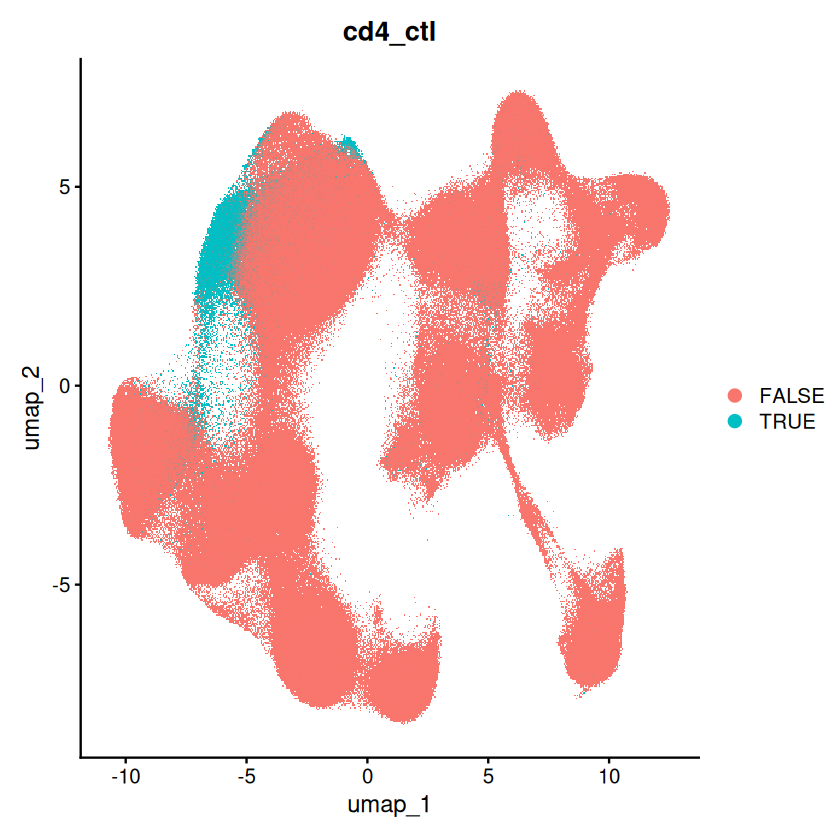

In [34]:
DimPlot(gut_allt_5p, group.by = "cd4_ctl")

In [35]:
gut_allt_5p$annotations  %>% table

.
           CTL             NA        Naive_1        Naive_2            Tcm 
         18771         241607          51934          11276          38339 
           Tfh            Th1         Th17_1         Th17_2            Th2 
         17587          54392          44199          10888          31992 
Treg activated     Treg naive 
         47505          19573 

In [36]:
gut_allt_5p$annotations  <- ifelse(is.na(gut_allt_5p$annotations), "NA", gut_allt_5p$annotations)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



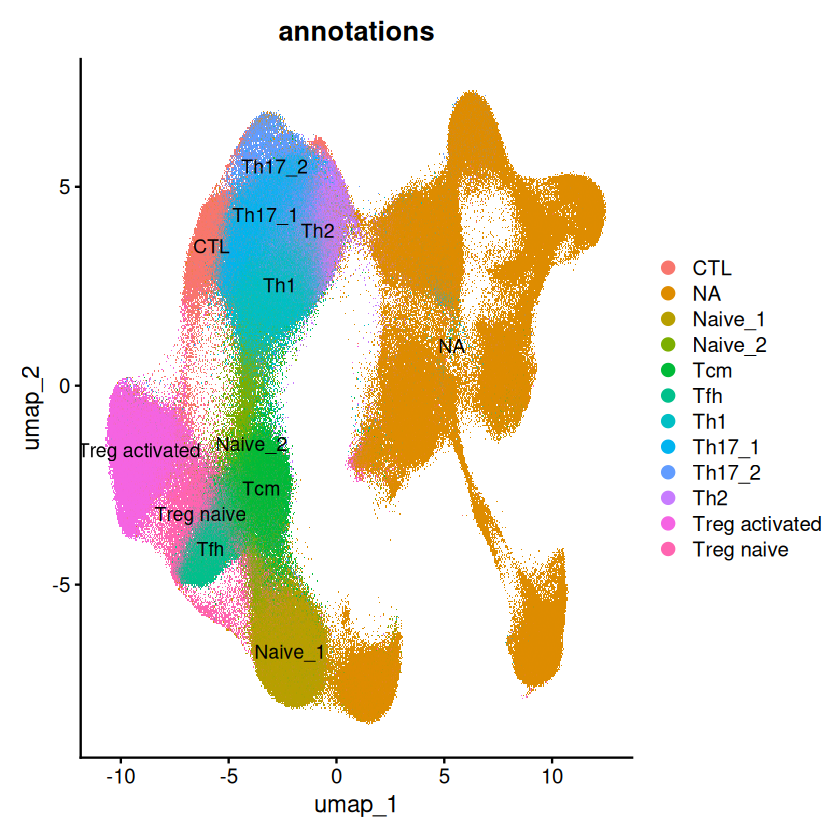

In [37]:
DimPlot(gut_allt_5p, group.by = "annotations", label = T)

In [38]:
gut_allt_5p$annotations_and_cd4_annot  <- ifelse(gut_allt_5p$annotations == "NA", gut_allt_5p$`integrated_snn_res.0.2`, gut_allt_5p$annotations)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



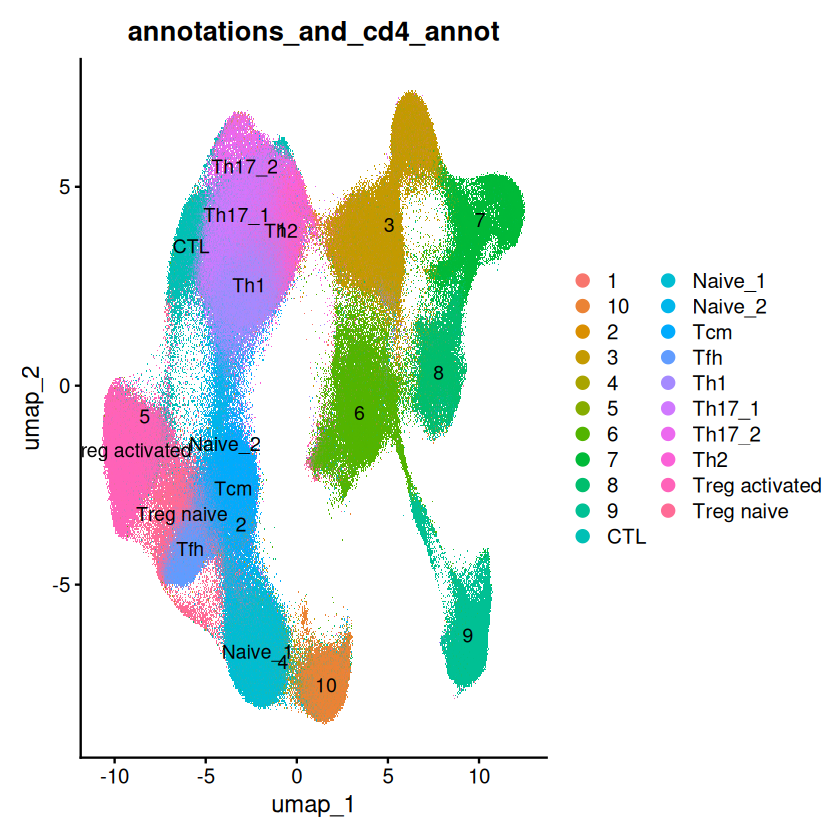

In [39]:
DimPlot(gut_allt_5p, group.by = "annotations_and_cd4_annot", label = T)

In [128]:
table(gut_allt_5p$annotations_and_cd4_annot)


             1             10              2              3              4 
          3949          23538            890          76705           1392 
             5              6              7              8              9 
           233          49326          32108          27463          26003 
           CTL        Naive_1        Naive_2            Tcm            Tfh 
         18771          51934          11276          38339          17587 
           Th1         Th17_1         Th17_2            Th2 Treg activated 
         54392          44199          10888          31992          47505 
    Treg naive 
         19573 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



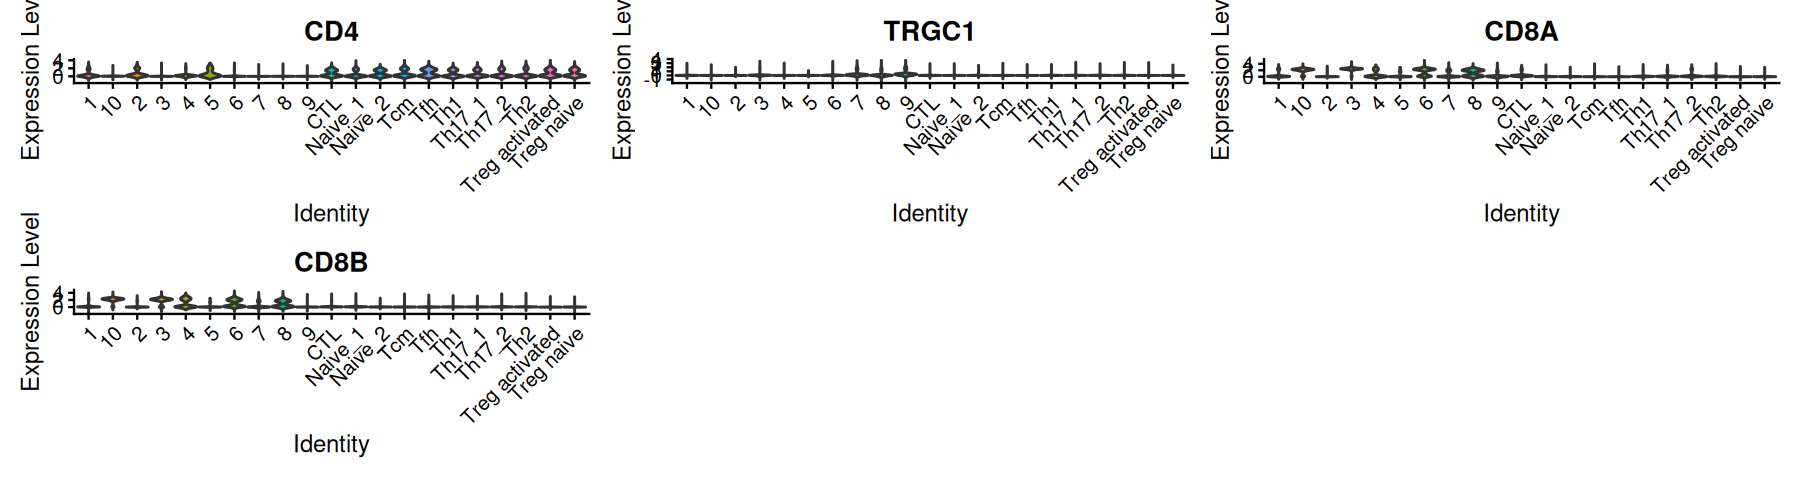

In [33]:
options(repr.plot.width = 15)
VlnPlot(gut_allt_5p, features = c("CD4","TRGC1", "CD8A","CD8B"), pt.size = 0, group.by = "annotations_and_cd4_annot")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



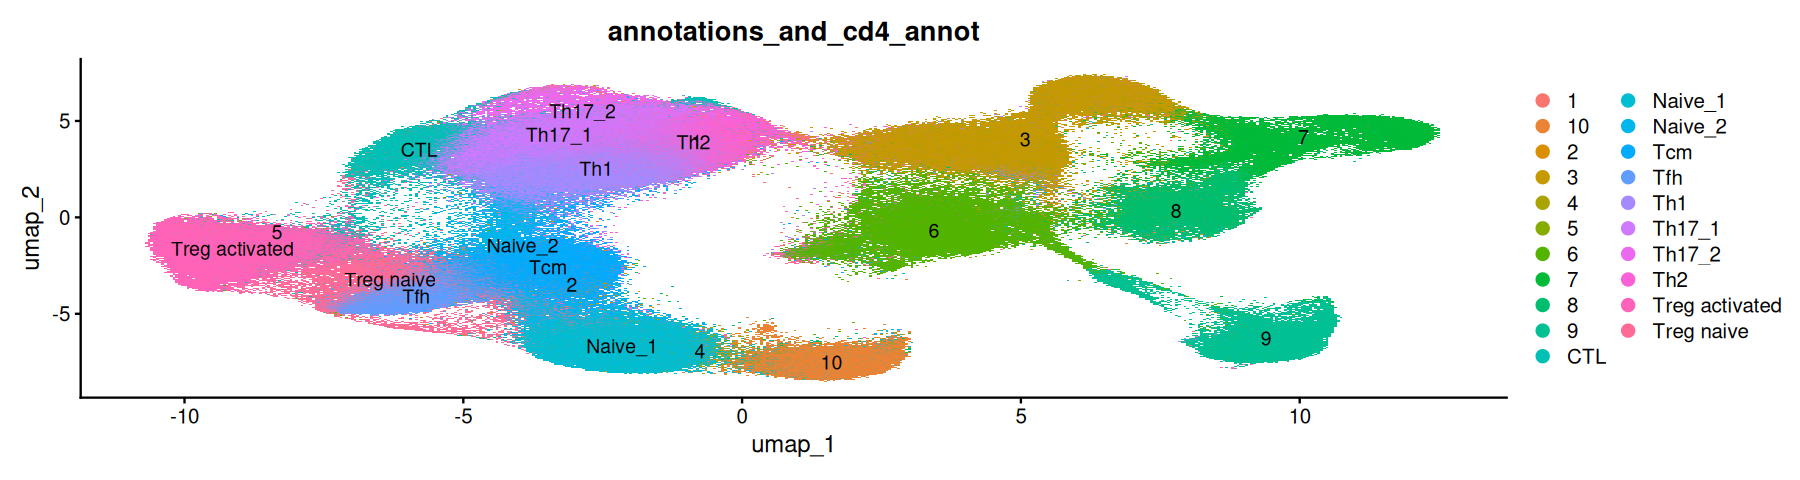

In [34]:
DimPlot(gut_allt_5p, group.by = "annotations_and_cd4_annot", label = T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



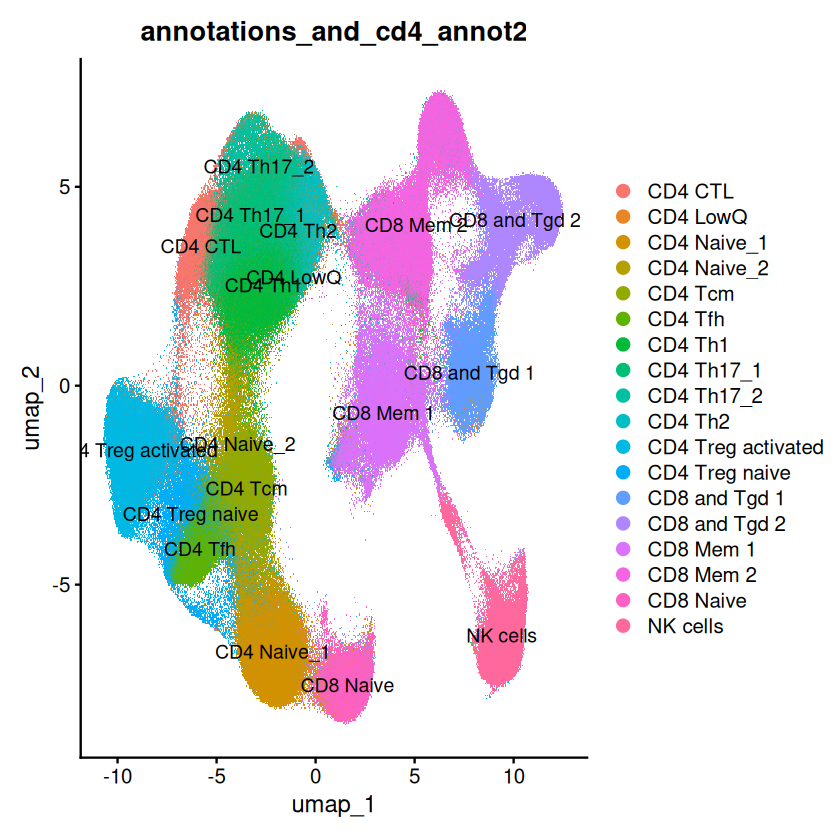

In [40]:
gut_allt_5p@meta.data <- gut_allt_5p@meta.data  %>% mutate(annotations_and_cd4_annot2 = case_when(
annotations != "NA" ~ paste("CD4", annotations),
annotations_and_cd4_annot ==  "10" ~ "CD8 Naive",                                                                         
annotations_and_cd4_annot == "6" ~ "CD8 Mem 1",
annotations_and_cd4_annot == "3" ~ "CD8 Mem 2",
annotations_and_cd4_annot == "8" ~ "CD8 and Tgd 1",
annotations_and_cd4_annot == "7" ~ "CD8 and Tgd 2",
annotations_and_cd4_annot == "9" ~ "NK cells",
TRUE ~ "CD4 LowQ"))
DimPlot(gut_allt_5p, group.by = "annotations_and_cd4_annot2", label = T)

In [51]:
levels(factor(gut_allt_5p$annotations_and_cd4_annot2))

[1] "CD4 CTL"            "CD4 LowQ"           "CD4 Naive_1"       
 [4] "CD4 Naive_2"        "CD4 Tcm"            "CD4 Tfh"           
 [7] "CD4 Th1"            "CD4 Th17_1"         "CD4 Th17_2"        
[10] "CD4 Th2"            "CD4 Treg activated" "CD4 Treg naive"    
[13] "CD8 and Tgd 1"      "CD8 and Tgd 2"      "CD8 Mem 1"         
[16] "CD8 Mem 2"          "CD8 Naive"          "NK cells"

In [42]:
pallete2 <- scales::hue_pal(h.start = 20) (11)
names(pallete2) <- c(1,9,4,8,6,2,3,0,10,5,7)
pallete2["5"] <- "#D4A6C8"

In [43]:
pallete2 <- c(scales::hue_pal(h.start = 20) (11),rep("grey88", times = 10))
names(pallete2) <- c("CD4 Naive_1","CD4 Naive_2",
                     "CD4 Tcm","CD4 Tfh","CD4 Treg naive",
                     "CD4 Treg activated","CD4 Th17_1",
                     "CD4 Th1","CD4 Th17_2","CD4 Th2","CD4 CTL", rep("grey88", times = 10))
pallete2["CD4 Th2"] <- "#D4A6C8"

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



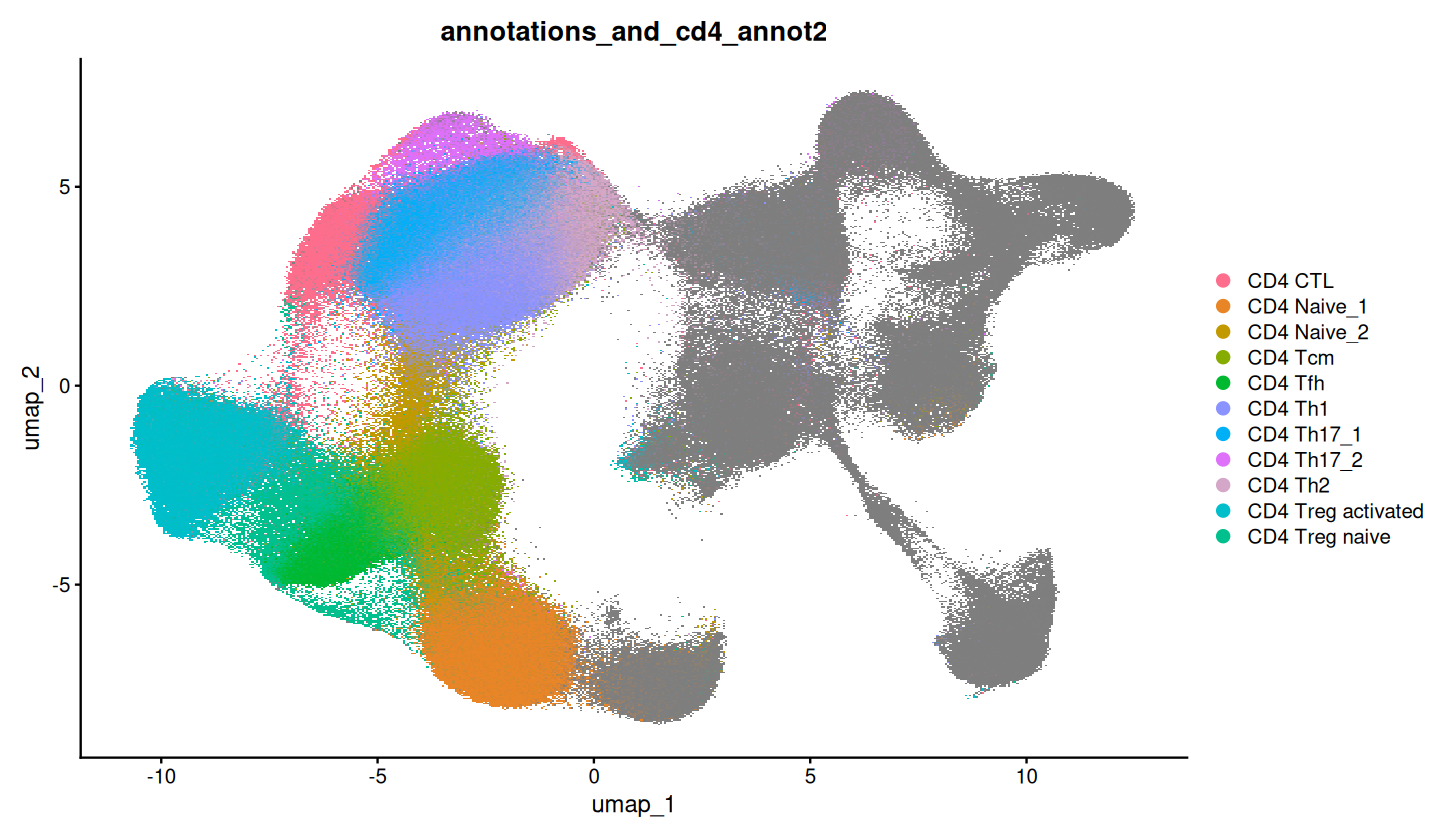

In [50]:
options(repr.plot.width = 12)
DimPlot(gut_allt_5p, group.by = "annotations_and_cd4_annot2", cols = pallete2)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



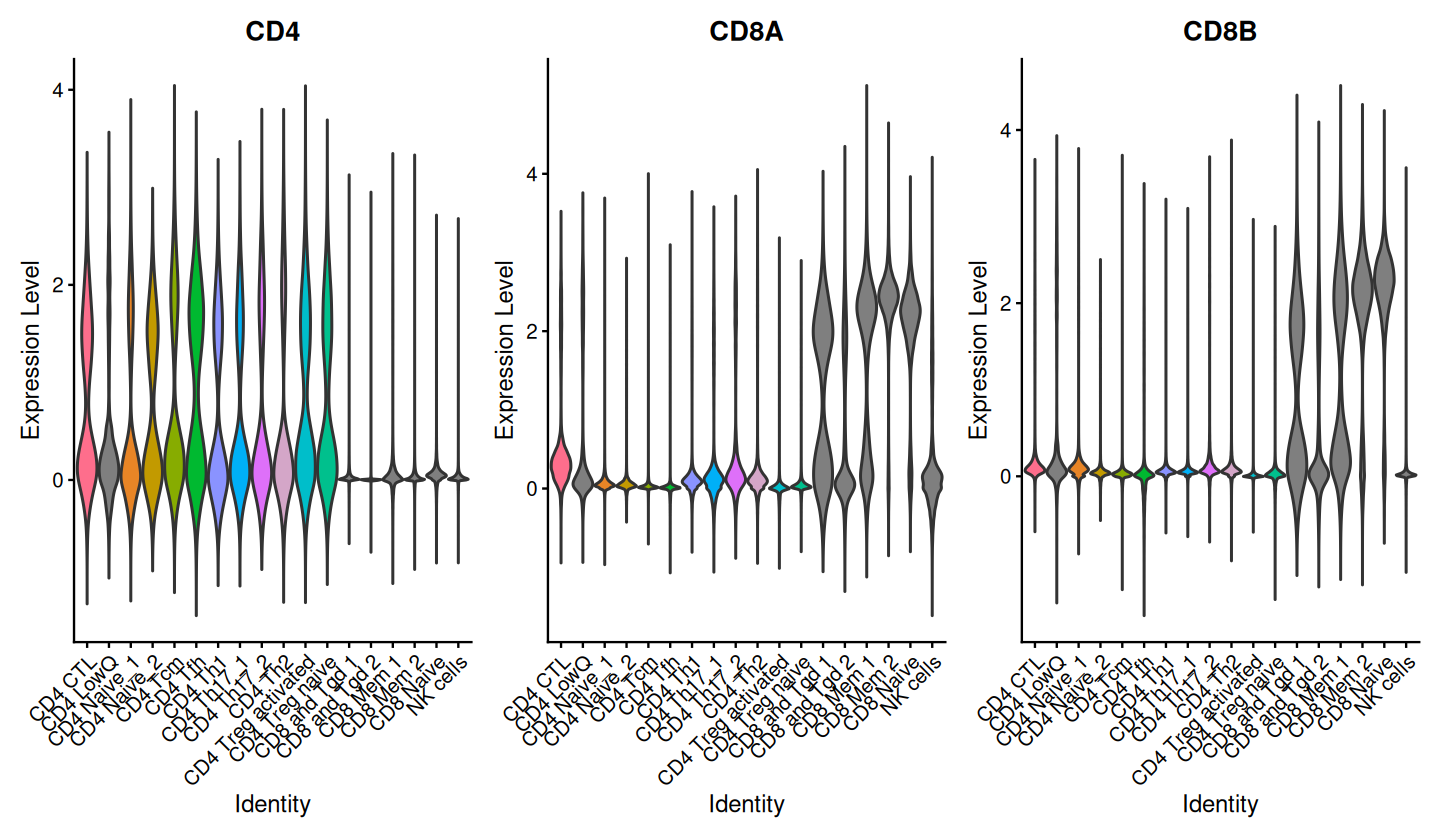

In [54]:
VlnPlot(gut_allt_5p, features = c("CD4","CD8A","CD8B"), pt.size = 0, 
       group.by = "annotations_and_cd4_annot2", cols = pallete2)

In [45]:
gut_allt_5p$annotations_with_numbers <- dplyr::recode(
  gut_allt_5p$annotations_and_cd4_annot2,
  
  "CD4 CTL"            = "11 CD4 CTL",
  "CD4 LowQ"           = "CD4 LowQ",
  "CD4 Naive_1"        = "1 CD4 Naive_1",
  "CD4 Naive_2"        = "2 CD4 Naive_2",
  "CD4 Tcm"            = "3 CD4 Tcm",
  "CD4 Tfh"            = "4 CD4 Tfh",
  "CD4 Th1"            = "8 CD4 Th1",
  "CD4 Th17_1"         = "7 CD4 Th17_1",
  "CD4 Th17_2"         = "10 CD4 Th17_2",
  "CD4 Th2"            = "9 CD4 Th2",
  "CD4 Treg activated" = "6 CD4 Treg activated",
  "CD4 Treg naive"     = "5 CD4 Treg naive",
  "CD8 and Tgd 1"      = "15 CD8 and Tgd 1",
  "CD8 and Tgd 2"      = "16 CD8 and Tgd 2",
  "CD8 Mem 1"          = "13 CD8 Mem 1",
  "CD8 Mem 2"          = "14 CD8 Mem 2",
  "CD8 Naive"          = "12 CD8 Naive",
  "NK cells"           = "17 NK cells"
)

In [46]:
gut_allt_5p$annotations_with_numbers <- factor(
  gut_allt_5p$annotations_with_numbers,
  levels = c(
    "1 CD4 Naive_1",
    "2 CD4 Naive_2",
    "3 CD4 Tcm",
    "4 CD4 Tfh",
    "5 CD4 Treg naive",
    "6 CD4 Treg activated",
    "7 CD4 Th17_1",
    "8 CD4 Th1",
    "9 CD4 Th2",
    "10 CD4 Th17_2",
    "11 CD4 CTL",
    "12 CD8 Naive",
    "13 CD8 Mem 1",
    "14 CD8 Mem 2",
    "15 CD8 and Tgd 1",
    "16 CD8 and Tgd 2",
    "17 NK cells",
    "CD4 LowQ"
  )
)

In [47]:
pallete2_new <- c(
  "1 CD4 Naive_1"        = unname(pallete2["CD4 Naive_1"]),
  "2 CD4 Naive_2"        = unname(pallete2["CD4 Naive_2"]),
  "3 CD4 Tcm"            = unname(pallete2["CD4 Tcm"]),
  "4 CD4 Tfh"            = unname(pallete2["CD4 Tfh"]),
  "5 CD4 Treg naive"     = unname(pallete2["CD4 Treg naive"]),
  "6 CD4 Treg activated" = unname(pallete2["CD4 Treg activated"]),
  "7 CD4 Th17_1"         = unname(pallete2["CD4 Th17_1"]),
  "8 CD4 Th1"            = unname(pallete2["CD4 Th1"]),
  "9 CD4 Th2"            = unname(pallete2["CD4 Th2"]),
  "10 CD4 Th17_2"        = unname(pallete2["CD4 Th17_2"]),
  "11 CD4 CTL"           = unname(pallete2["CD4 CTL"]),
  "CD4 LowQ"             = unname(pallete2["CD4 LowQ"]),
  "12 CD8 Naive"         = unname(pallete2["CD8 Naive"]),
  "13 CD8 Mem 1"         = unname(pallete2["CD8 Mem 1"]),
  "14 CD8 Mem 2"         = unname(pallete2["CD8 Mem 2"]),
  "15 CD8 and Tgd 1"     = unname(pallete2["CD8 and Tgd 1"]),
  "16 CD8 and Tgd 2"     = unname(pallete2["CD8 and Tgd 2"]),
  "17 NK cells"          = unname(pallete2["NK cells"])
)

In [48]:
pallete2_new <- pallete2_new[c(
  setdiff(names(pallete2_new), "CD4 LowQ"),
  "CD4 LowQ"
)]

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Warning message:
“Removed 241607 rows containing missing values or values outside the scale range
(`geom_scattermore()`).”


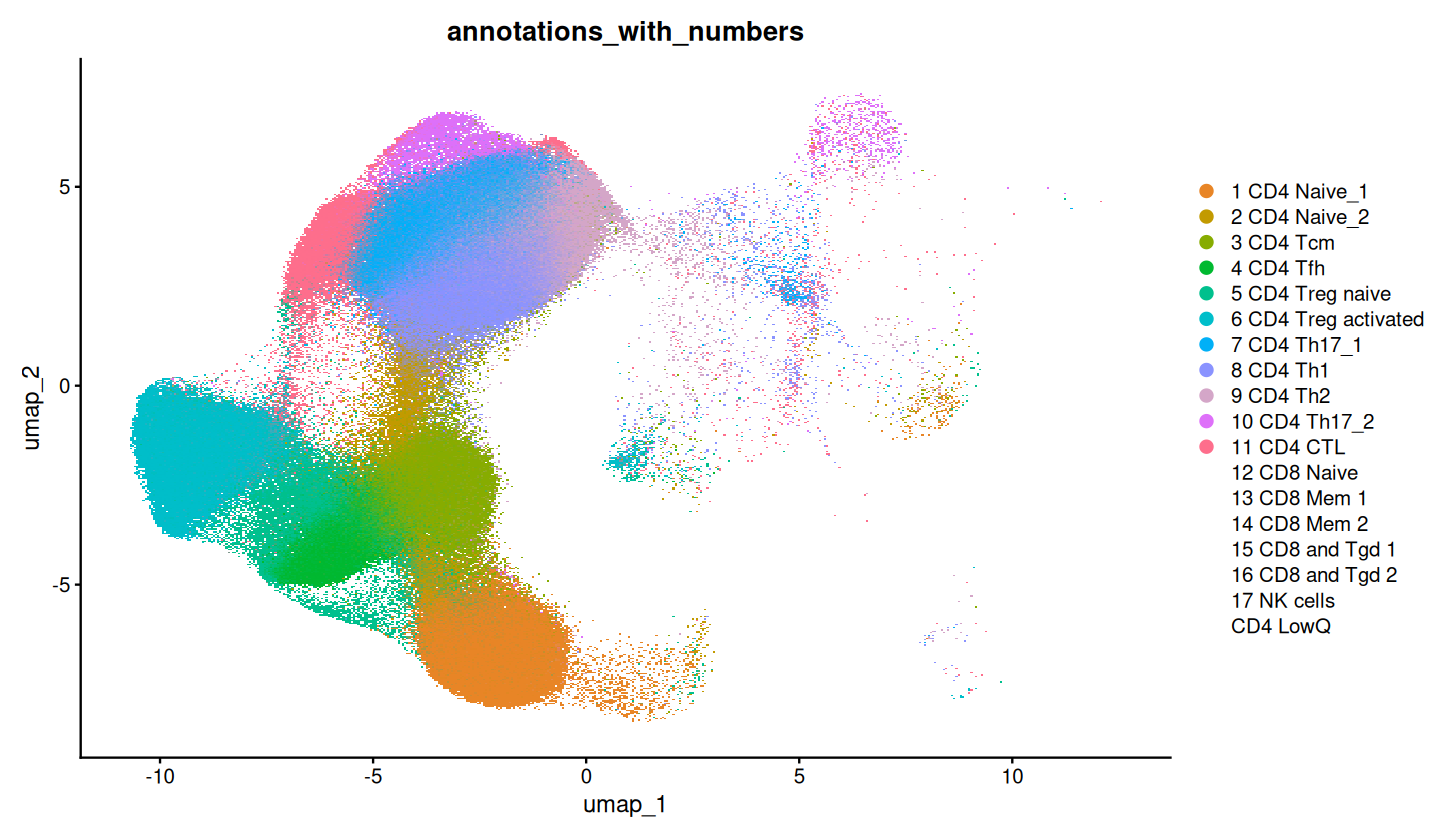

In [49]:
options(repr.plot.width = 12)
DimPlot(gut_allt_5p, group.by = "annotations_with_numbers", cols = pallete2_new)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



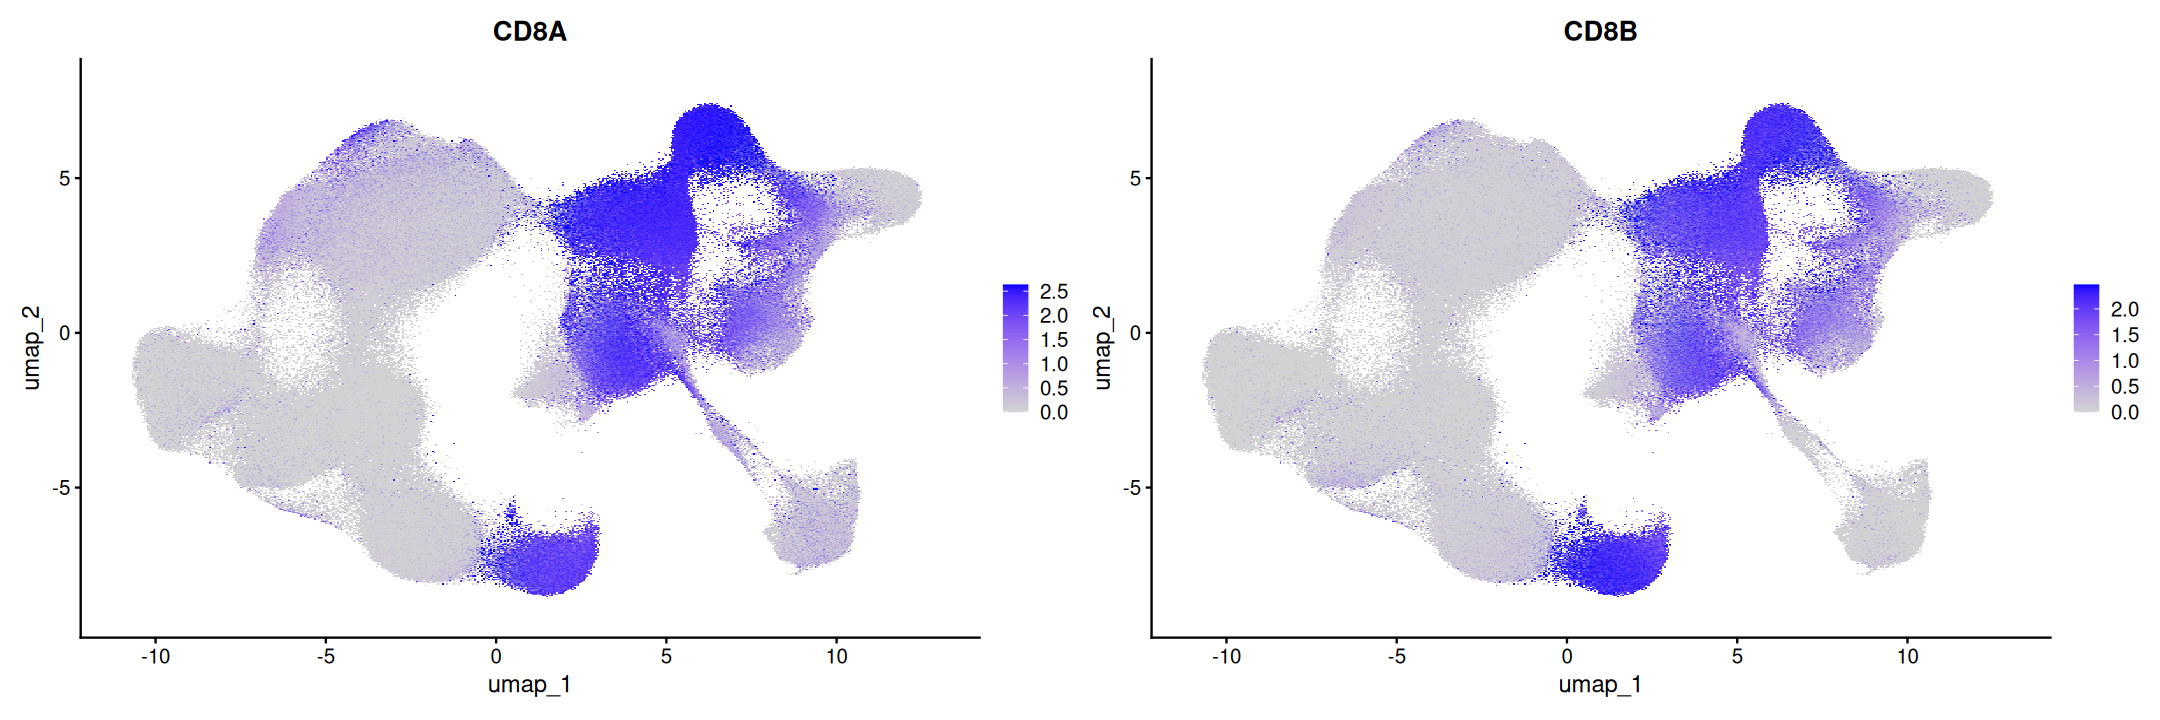

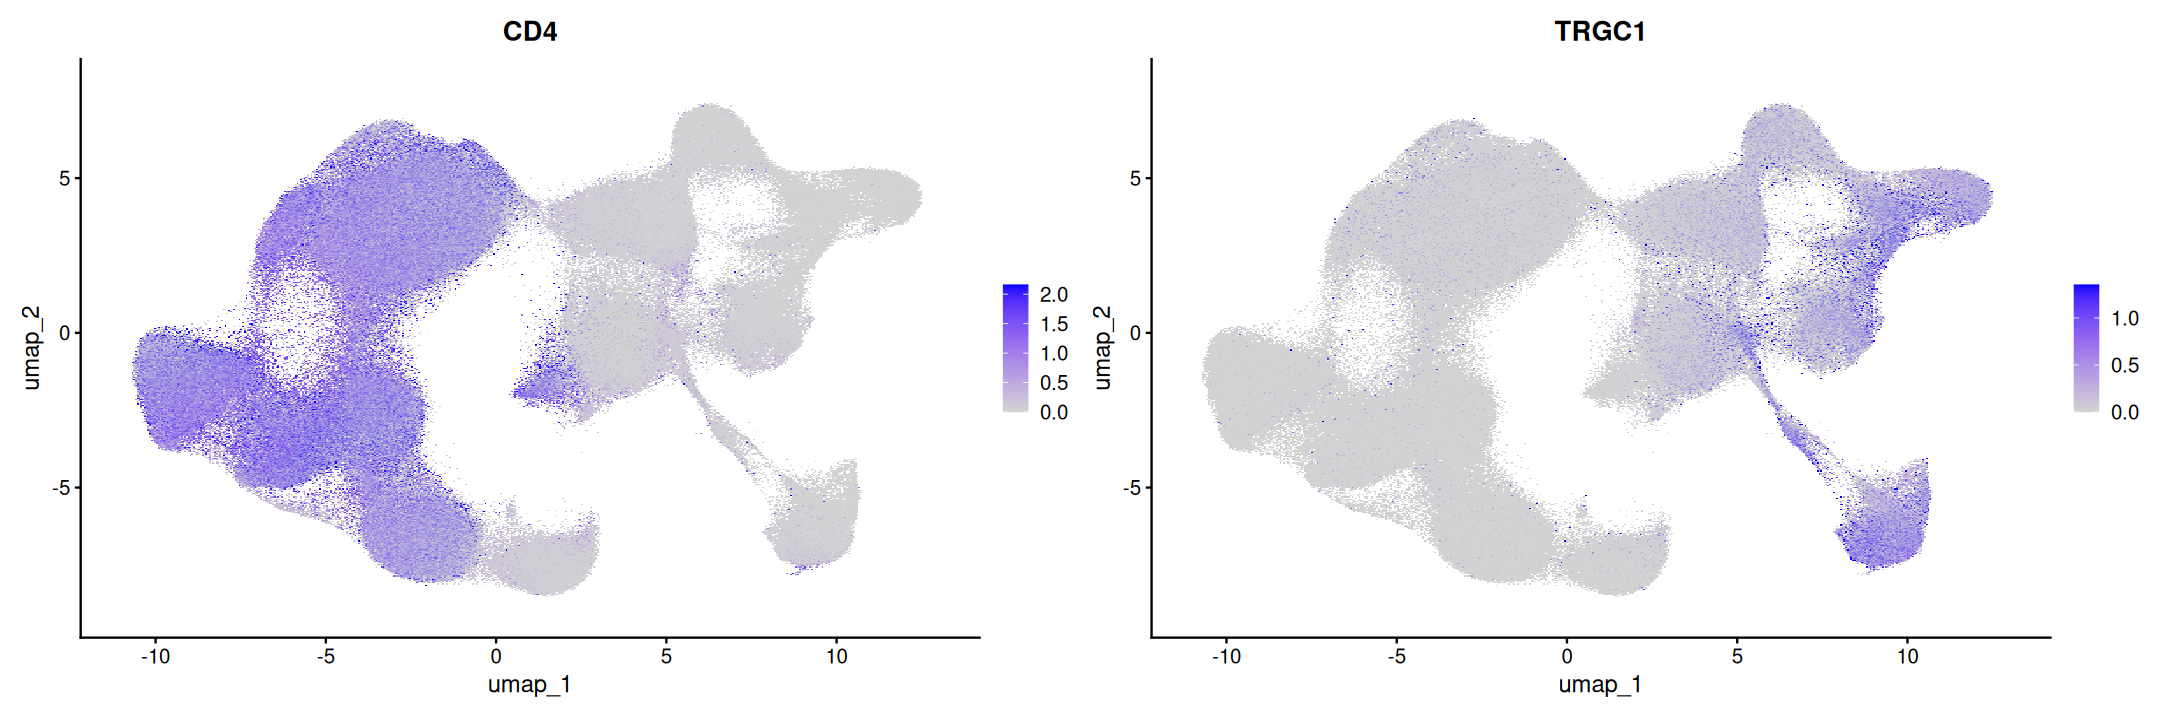

In [136]:
options(repr.plot.width = 18, repr.plot.height = 6)

FeaturePlot(gut_allt_5p, features = c("CD8A","CD8B"), ncol = 2, min.cutoff = 0, max.cutoff = "q95")

FeaturePlot(gut_allt_5p, features = c("CD4","TRGC1"), ncol = 2, min.cutoff = 0, max.cutoff = "q95")

In [48]:
DefaultAssay(gut_allt_5p)  <- "RNA"

In [51]:
genes <- c("CD8A", "CD8B", "CD4")

# Extract expression and annotations
df <- FetchData(
  gut_allt_5p,
  vars = c(genes, "annotations_with_numbers"),
  layer = "counts"
)

# Calculate percentage of positive cells per annotation
df_summary <- df %>%
  pivot_longer(
    cols = all_of(genes),
    names_to = "gene",
    values_to = "expression"
  ) %>%
  group_by(annotations_with_numbers, gene) %>%
  summarise(
    percent_positive = mean(expression > 0) * 100,
    .groups = "drop"
  )

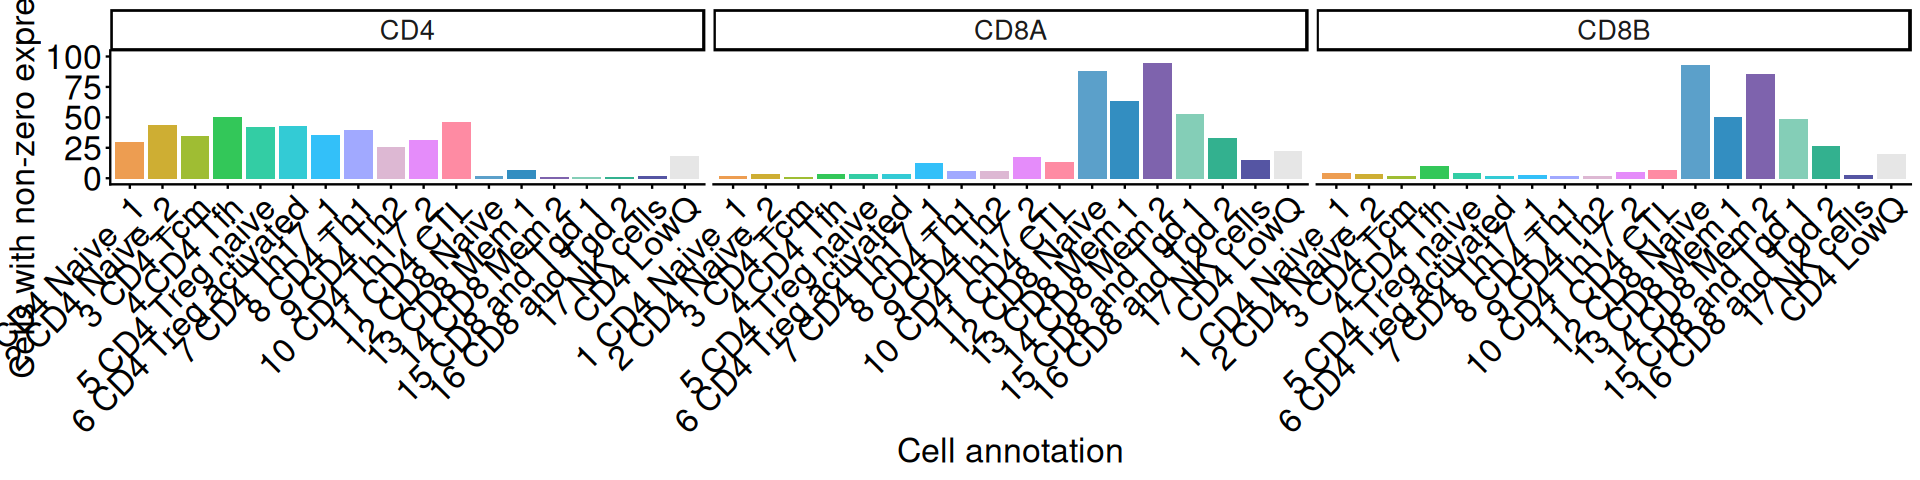

In [52]:
options(repr.plot.width = 16, repr.plot.height = 4)
ggplot(df_summary,
       aes(x = annotations_with_numbers,
           y = percent_positive,
           fill = annotations_with_numbers)) +
  geom_col(width = 0.85, alpha = 0.8) +
  facet_wrap(~ gene, nrow = 1) +
  scale_fill_manual(values = pallete2_new) +
  scale_y_continuous(limits = c(0, 100)) +
  labs(
    x = "Cell annotation",
    y = "Cells with non-zero expression (%)"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "none"
  ) +
ggtheme()

In [55]:

ggsave("figures/barplot_gut_cd4_cd8_5p.svg", width = 34, height = 12.5, units = "cm")
ggsave("figures/barplot_gut_cd4_cd8_5p.png", width = 34, height = 12.5, units = "cm")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



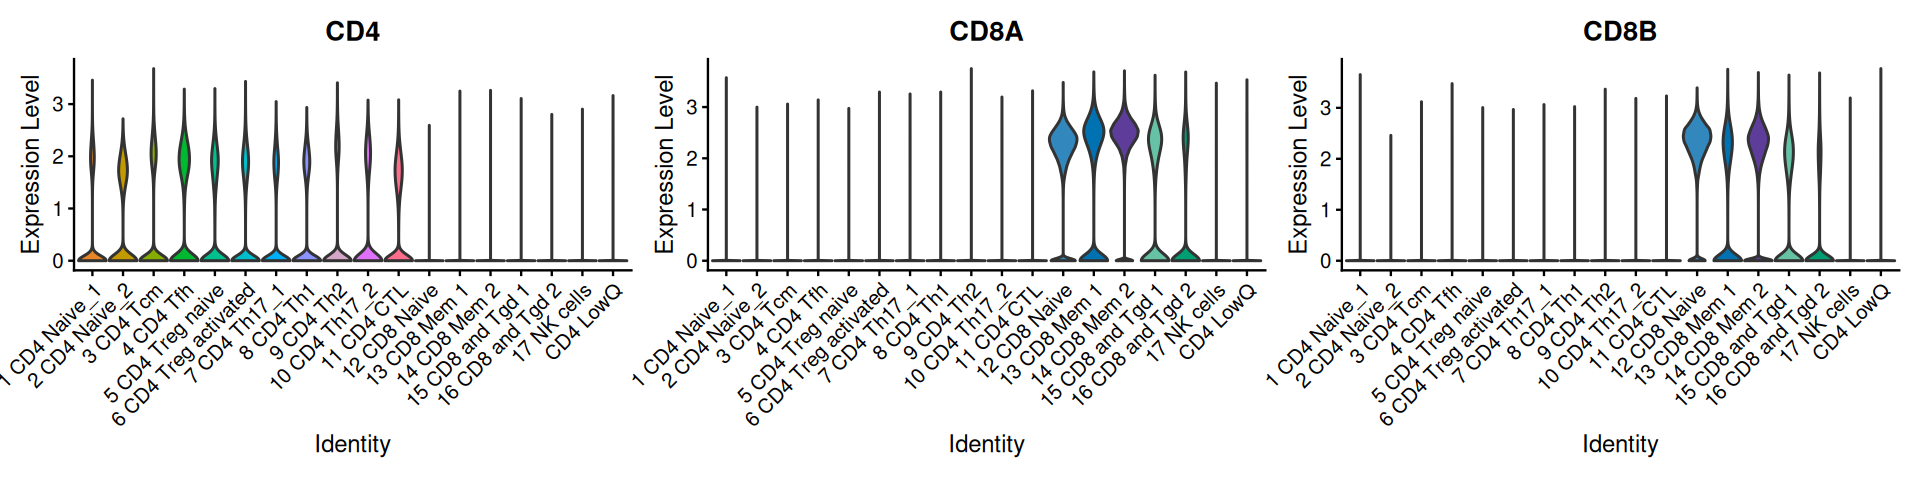

In [150]:
options(repr.plot.width = 16, repr.plot.height = 4)
VlnPlot(gut_allt_5p, features = c("CD4","CD8A","CD8B"), pt.size = 0, 
       group.by = "annotations_with_numbers", cols = pallete2_new, assay = "RNA")

ggsave("figures/vlnplot_cd4_cd8_5p.svg", width = 32, height = 11, units = "cm")
ggsave("figures/vlnplot_cd4_cd8_5p.png", width = 32, height = 11, units = "cm")

### 3p

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



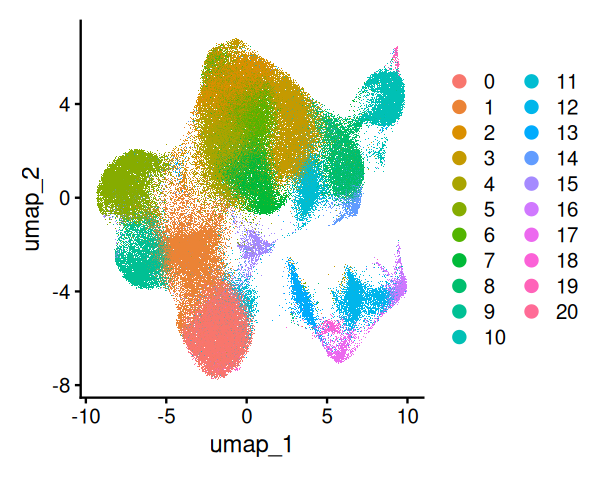

In [129]:
DimPlot(gut_allt_3p)

In [123]:
gut_allt_3p@reductions$umap@cell.embeddings[,1]  <- -1*gut_allt_3p@reductions$umap@cell.embeddings[,1]

gut_allt_3p@reductions$umap@cell.embeddings[,2]  <- -1*gut_allt_3p@reductions$umap@cell.embeddings[,2]

gut_allt_3p@meta.data <- gut_allt_3p@meta.data  %>% mutate(annotations_coarse = 
                                                                       recode_factor(integrated_snn_res.0.3, 
"0" = "CD4 Th17",                                                                         
"1" = "Naive",
"2" = "CD8 and Tgd",
"3" = "CD4 Tcm",
"4" = "CD4 Treg",
"5" = "CD8 and Tgd",
"6" = "CD8 and Tgd",
"7" = "NK cells",
"8" = "CD4 Tcm",
"9" = "CD4 Th17",
"10" = "CD8 and Tgd"))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



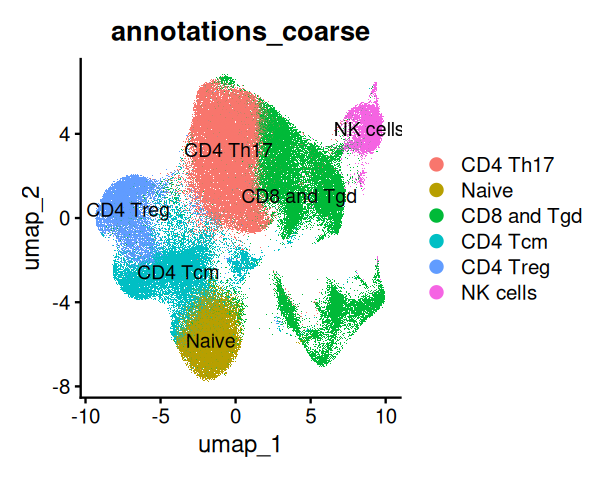

In [124]:
options(repr.plot.width = 5, repr.plot.height = 4)
DimPlot(gut_allt_3p, group.by = "annotations_coarse", label = T)

In [61]:
gut_cd4_3p  <- readRDS("../251029_VN_PREDICT3/data/SCP/Gut_CD4_3p_updated.rds")

In [125]:
gut_cd4_3p_md  <- read_csv("tables/261103_md_cd4_3p.csv")

New names:
• `` -> `...1`
Rows: 175466 Columns: 37
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (19): ...1, SingleR_HPCA, orig.ident, smp_id, patient, time, tissue, lay...
dbl (18): nCount_RNA, nFeature_RNA, RNA_snn_res.0.3, seurat_clusters, percen...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [126]:
gut_cd4_3p_md

...1,SingleR_HPCA,nCount_RNA,nFeature_RNA,RNA_snn_res.0.3,seurat_clusters,orig.ident,smp_id,percent.mt,patient,⋯,annotations_coarse,cd4,cd8,cd4_or_cd8,cd4_or_cd8_2,integrated_snn_res.1,integrated_snn_res.1.1,integrated_snn_res.1.2,data_folder,annotations2
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<chr>,⋯,<chr>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
Cell516_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,2290,995,5,6,NA,NA,NA,p002,⋯,CD4 Tcm,0,0,Unknown,CD4,9,10,11,p002 COL EPI T0D,Tfh
Cell6091_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,2117,899,5,0,NA,NA,NA,p002,⋯,CD4 Tcm,0,0,Unknown,CD4,8,6,5,p002 COL EPI T0D,Tcm
Cell7487_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,1703,762,4,3,NA,NA,NA,p002,⋯,CD4 Th17,0,0,Unknown,CD4,1,2,10,p002 COL EPI T0D,Th17
Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,1379,634,0,1,NA,NA,NA,p002,⋯,CD4 Th17,1,0,CD4,CD4,2,0,4,p002 COL LP T0D,Mixed Teff1
Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,1331,572,1,2,NA,NA,NA,p002,⋯,CD4 Tcm,0,0,Unknown,CD4,0,8,7,p002 COL LP T0D,Naive
Cell9_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,703,361,1,0,NA,NA,NA,p002,⋯,CD4 Tcm,0,0,Unknown,CD4,8,9,18,p002 COL LP T0D,Tcm
Cell16_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,1439,660,3,0,NA,NA,NA,p002,⋯,CD4 Tcm,0,0,Unknown,CD4,3,3,2,p002 COL LP T0D,Tcm
Cell17_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,1915,748,1,0,NA,NA,NA,p002,⋯,CD4 Tcm,0,0,Unknown,CD4,10,3,14,p002 COL LP T0D,Tcm
Cell18_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,1079,499,5,0,NA,NA,NA,p002,⋯,CD4 Tcm,1,0,CD4,CD4,3,3,2,p002 COL LP T0D,Tcm


In [133]:
colnames(gut_cd4_3p_md)

[1] "...1"                   "SingleR_HPCA"           "nCount_RNA"            
 [4] "nFeature_RNA"           "RNA_snn_res.0.3"        "seurat_clusters"       
 [7] "orig.ident"             "smp_id"                 "percent.mt"            
[10] "patient"                "time"                   "tissue"                
[13] "layer"                  "prime"                  "RNA_snn_res.0.2"       
[16] "RNA_snn_res.0.6"        "RNA_snn_res.0.7"        "RNA_snn_res.0.8"       
[19] "manual_annotation"      "smp_id2"                "disease"               
[22] "antiTNF_response"       "barcode"                "integrated_snn_res.0.3"
[25] "integrated_snn_res.0.5" "integrated_snn_res.0.7" "integrated_snn_res.0.9"
[28] "annotations_coarse"     "cd4"                    "cd8"                   
[31] "cd4_or_cd8"             "cd4_or_cd8_2"           "integrated_snn_res.1"  
[34] "integrated_snn_res.1.1" "integrated_snn_res.1.2" "data_folder"           
[37] "annotations2"

In [134]:
gut_cd4_3p_md$annotations2  %>% table

.
      CD4 CTL   Mixed Teff1   Mixed Teff2         Naive Proliferating 
         4436         31438         13007         30966          3803 
          Tcm           Tfh          Th17          Treg 
        33199          8046         27297         23274 

In [145]:
md_3p  <- gut_allt_3p@meta.data

In [146]:
md_3p$barcode  <- colnames(gut_allt_3p)

In [140]:
md_3p_cd4   <- gut_cd4_3p_md
md_3p_cd4$barcode  <- gut_cd4_3p_md$`...1`

In [142]:
rownames(md_3p_cd4)  <- gut_cd4_3p_md$`...1`

Warning message:
“Setting row names on a tibble is deprecated.”


In [147]:
md_3p  <- left_join(md_3p  %>% dplyr::select(-annotations), md_3p_cd4  %>% dplyr::select(annotations = annotations2, barcode))

Joining with `by = join_by(barcode)`


In [73]:
colnames(gut_allt_3p@meta.data)

[1] "SingleR_HPCA"           "nCount_RNA"             "nFeature_RNA"          
 [4] "RNA_snn_res.0.3"        "seurat_clusters"        "orig.ident"            
 [7] "smp_id"                 "percent.mt"             "patient"               
[10] "time"                   "tissue"                 "layer"                 
[13] "prime"                  "RNA_snn_res.0.2"        "RNA_snn_res.0.6"       
[16] "RNA_snn_res.0.7"        "RNA_snn_res.0.8"        "manual_annotation"     
[19] "smp_id2"                "disease"                "antiTNF_response"      
[22] "barcode"                "integrated_snn_res.0.3" "integrated_snn_res.0.5"
[25] "integrated_snn_res.0.7" "integrated_snn_res.0.9" "annotations_coarse"

In [148]:
head(rownames(md_3p))

[1] "1" "2" "3" "4" "5" "6"

In [149]:
head(colnames(gut_allt_3p))

[1] "Cell516_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1" 
[2] "Cell769_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1" 
[3] "Cell2650_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[4] "Cell2740_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[5] "Cell2872_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[6] "Cell3164_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"

In [150]:
length(rownames(md_3p))
length(colnames(gut_allt_3p))

[1] 283277

[1] 283277

In [151]:
rownames(md_3p)  <- md_3p$barcode

In [152]:
all.equal(rownames(md_3p), colnames(gut_allt_3p))

[1] TRUE

In [153]:
head(rownames(md_3p))

[1] "Cell516_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1" 
[2] "Cell769_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1" 
[3] "Cell2650_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[4] "Cell2740_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[5] "Cell2872_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[6] "Cell3164_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"

In [154]:
gut_allt_3p@meta.data  <- md_3p

In [155]:
rownames(gut_allt_3p@meta.data)  %>% head

[1] "Cell516_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1" 
[2] "Cell769_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1" 
[3] "Cell2650_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[4] "Cell2740_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[5] "Cell2872_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"
[6] "Cell3164_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1"

In [156]:
gut_allt_3p$annotations  <- ifelse(is.na(gut_allt_3p$annotations), "NA", gut_allt_3p$annotations)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



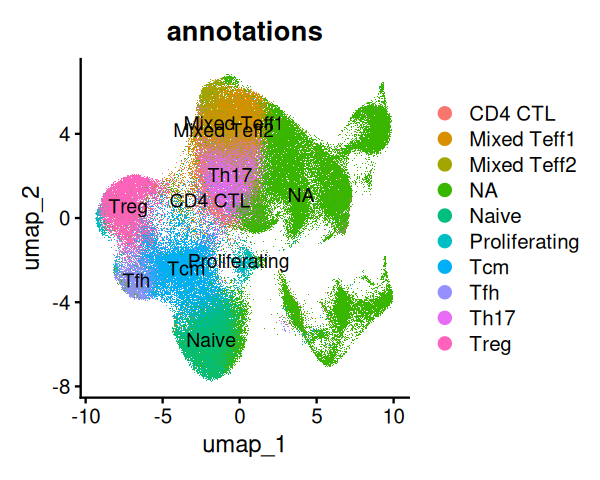

In [157]:
DimPlot(gut_allt_3p, group.by = "annotations", label = T)

In [158]:
gut_allt_3p$annotations_and_cd4_annot  <- ifelse(gut_allt_3p$annotations == "NA", 
                                                 gut_allt_3p$`integrated_snn_res.0.3`, gut_allt_3p$annotations)

In [159]:
table(gut_allt_3p$annotations_and_cd4_annot)


            1            10            11             2             3 
         3365          7059          6359          7207         35673 
            4             5             6             7             8 
          410           356         18997         14057         13082 
            9       CD4 CTL   Mixed Teff1   Mixed Teff2         Naive 
         1246          4436         31438         13007         30966 
Proliferating           Tcm           Tfh          Th17          Treg 
         3803         33199          8046         27297         23274 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



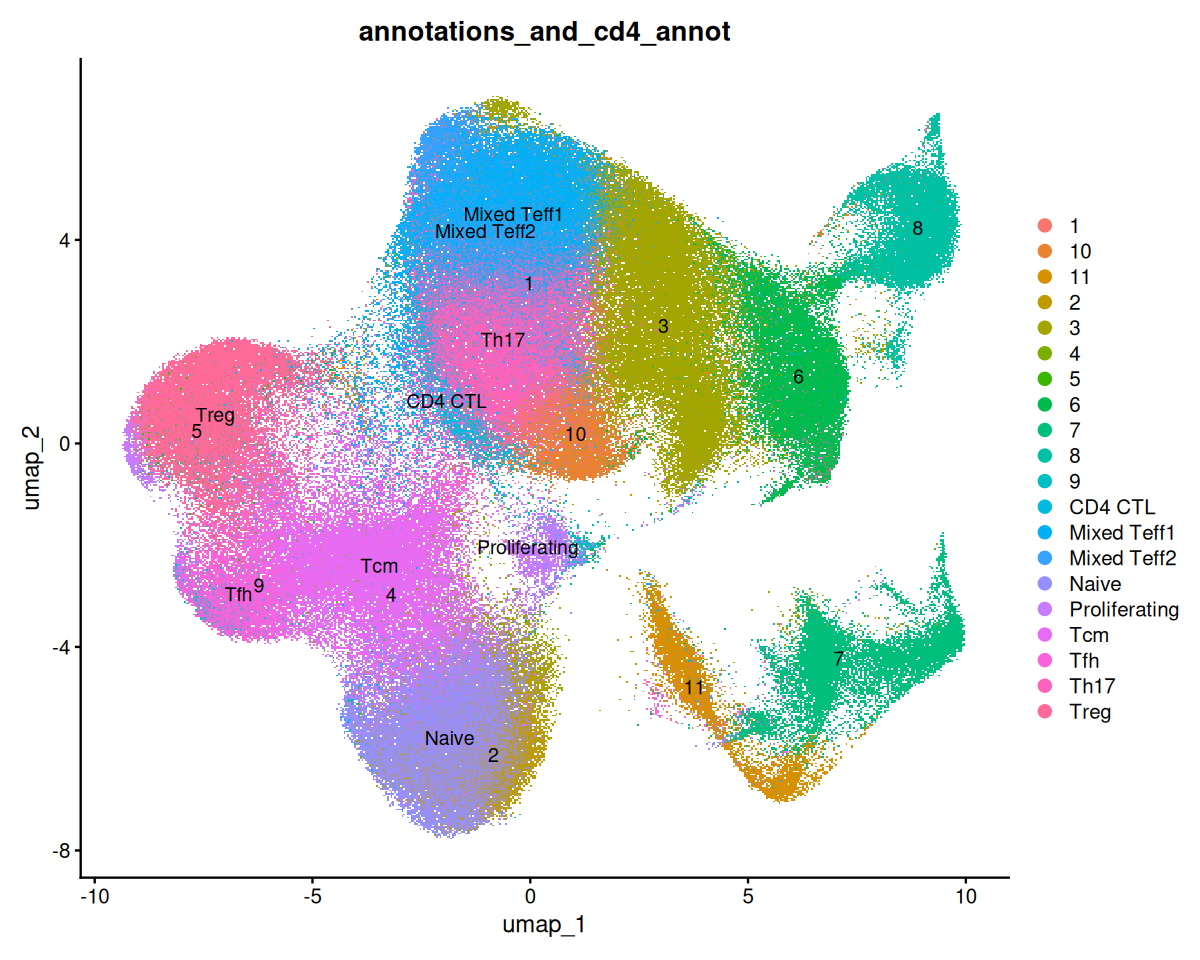

In [160]:
options(repr.plot.width = 10, repr.plot.height = 8)
DimPlot(gut_allt_3p, group.by = "annotations_and_cd4_annot", label = T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Warning message:
“Could not find CD4 in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



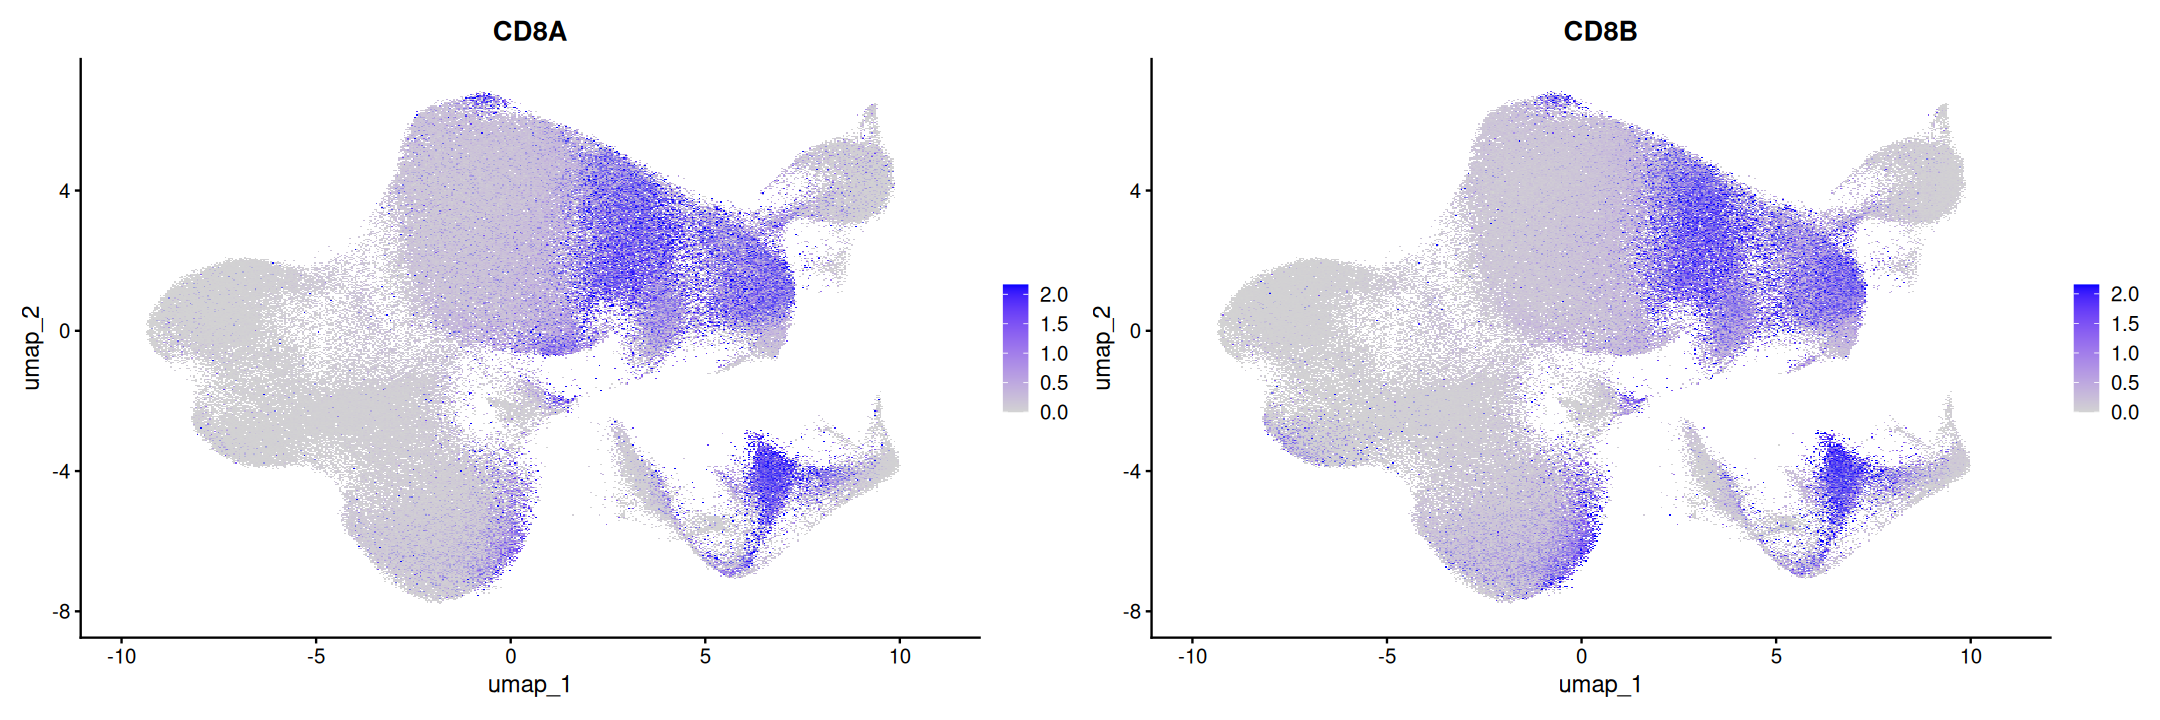

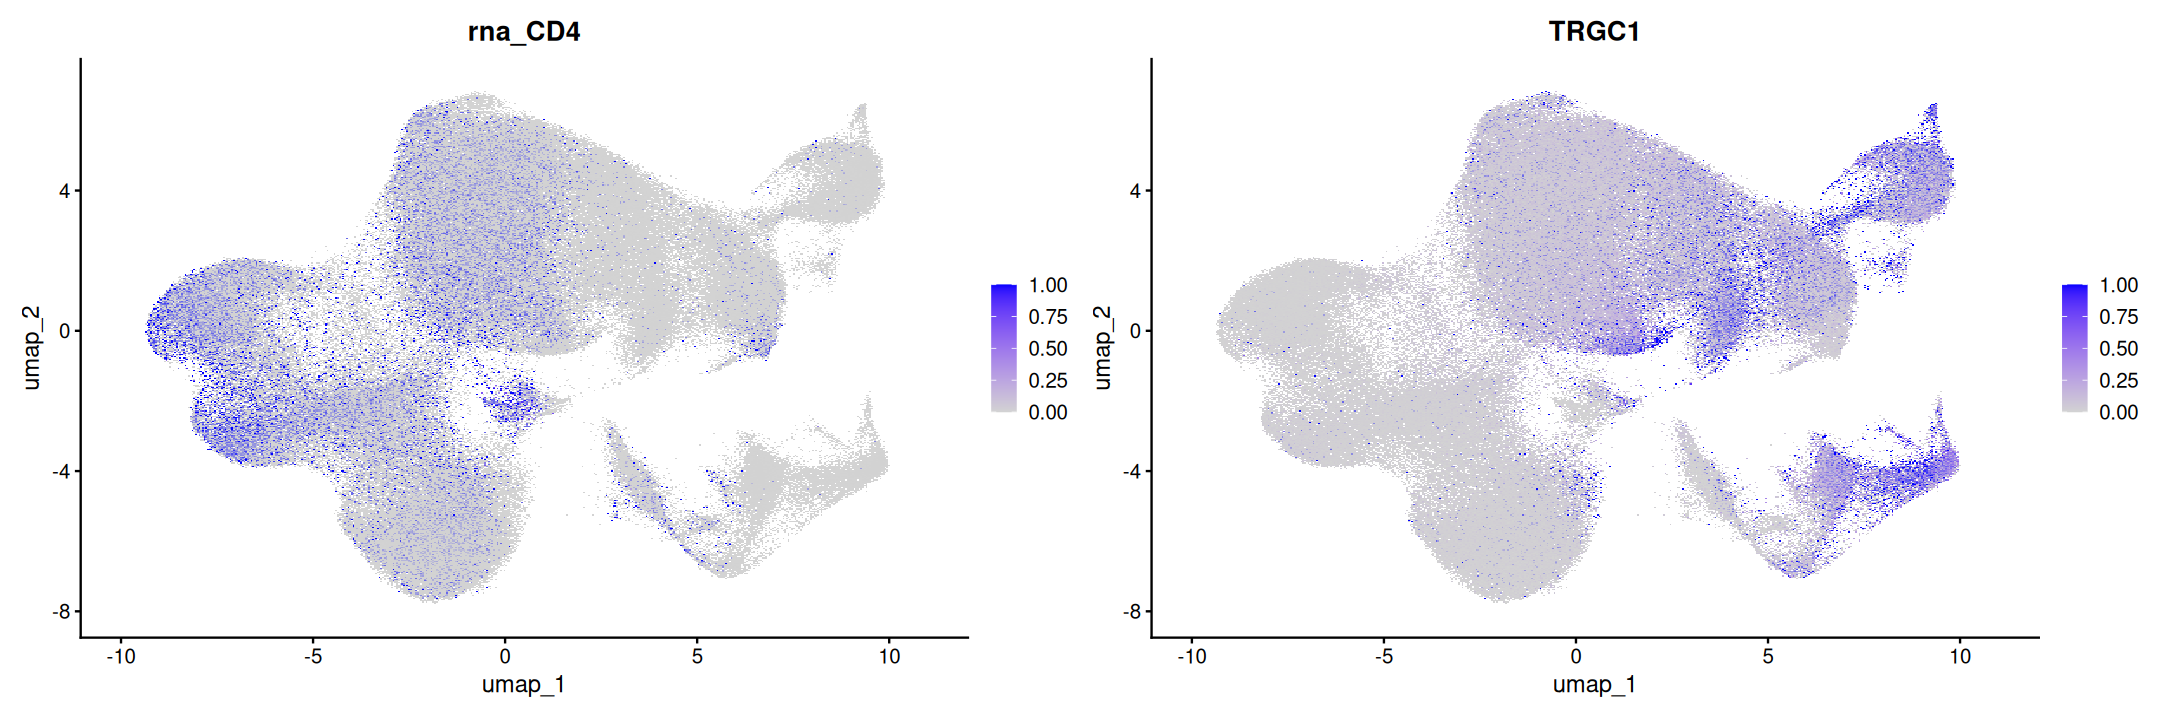

In [161]:
options(repr.plot.width = 18, repr.plot.height = 6)

FeaturePlot(gut_allt_3p, features = c("CD8A","CD8B"), ncol = 2, min.cutoff = 0, max.cutoff = "q95")

FeaturePlot(gut_allt_3p, features = c("CD4","TRGC1"), ncol = 2, min.cutoff = 0, max.cutoff = 1)


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



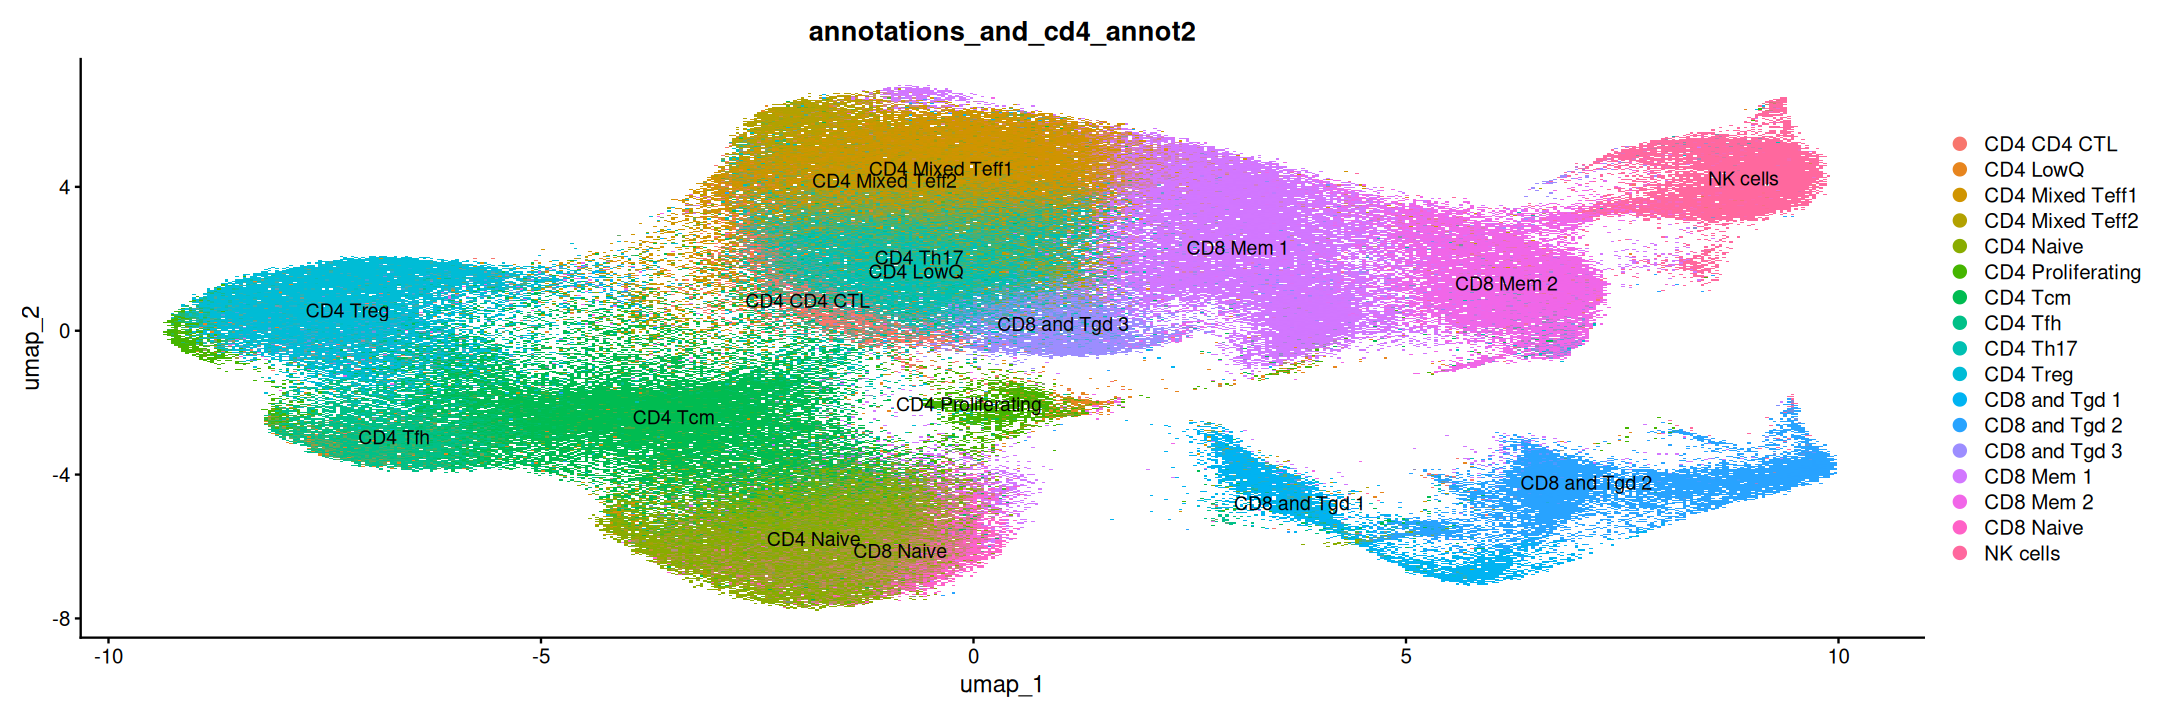

In [163]:
gut_allt_3p@meta.data <- gut_allt_3p@meta.data  %>% mutate(annotations_and_cd4_annot2 = case_when(
annotations != "NA" ~ paste("CD4", annotations),
annotations_and_cd4_annot ==  "2" ~ "CD8 Naive",                                                                         
annotations_and_cd4_annot == "3" ~ "CD8 Mem 1",
annotations_and_cd4_annot == "6" ~ "CD8 Mem 2",
annotations_and_cd4_annot == "11" ~ "CD8 and Tgd 1",
    annotations_and_cd4_annot == "10" ~ "CD8 and Tgd 3",

annotations_and_cd4_annot == "7" ~ "CD8 and Tgd 2",
annotations_and_cd4_annot == "8" ~ "NK cells",
TRUE ~ "CD4 LowQ"))
DimPlot(gut_allt_3p, group.by = "annotations_and_cd4_annot2", label = T)

In [169]:
pallete3 <- c("CD4 Naive" = "#e88526ff",
"CD4 Tcm" = "#c19a00ff",
"CD4 Tfh" = "#00b930ff",
"CD4 Treg" = "#1bc799ff",
                    "CD4 Th17" = "#00b0f7ff",
                     "CD4 Mixed Teff2" = "#8a93ffff",
"CD4 Proliferating" = "#dd70f8ff",
"CD4 Mixed Teff1" = "#D4A6C8",
"CD4 CD4 CTL" = "#fe6e8cff",
 "CD8 and Tgd 1" = "#66C2A5",
  "CD8 and Tgd 2" = "#009E73",
   "CD8 and Tgd 3" = "#80bde0ff",
 "CD8 Mem 2"     = "#5E3C99",
  "CD8 Mem 1"     = "#0072B2",
  "CD8 Naive"     =  "#3288BD",
  "NK cells"      = "#2B2B8C",
              "CD4 LowQ" = "grey88")

In [170]:
pallete3_numbered <- c(
  "1 CD4 Naive"       = "#e88526ff",
  "2 CD4 Tcm"         = "#c19a00ff",
  "3 CD4 Tfh"         = "#00b930ff",
  "4 CD4 Treg"        = "#1bc799ff",
  "5 CD4 Mixed Teff2"         = "#8a93ffff",
  "6 CD4 Th17"        = "#00b0f7ff",
  "7 CD4 Mixed Teff1"         = "#D4A6C8",
  "8 CD4 CTL"         = "#fe6e8cff",
  "9 CD4 Proliferating"         = "#dd70f8ff",
  "10 CD8 Naive"      = "#3288BD",
  "11 CD8 Mem 1"      = "#0072B2",
  "12 CD8 Mem 2"      = "#5E3C99",
  "13 NK cells"       = "#2B2B8C",
  "14 CD8 and Tgd 1"  = "#66C2A5",
  "15 CD8 and Tgd 2"  = "#009E73",
  "16 CD8 and Tgd 3"  = "#80bde0ff",
  "CD4 LowQ"          = "grey88"
)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



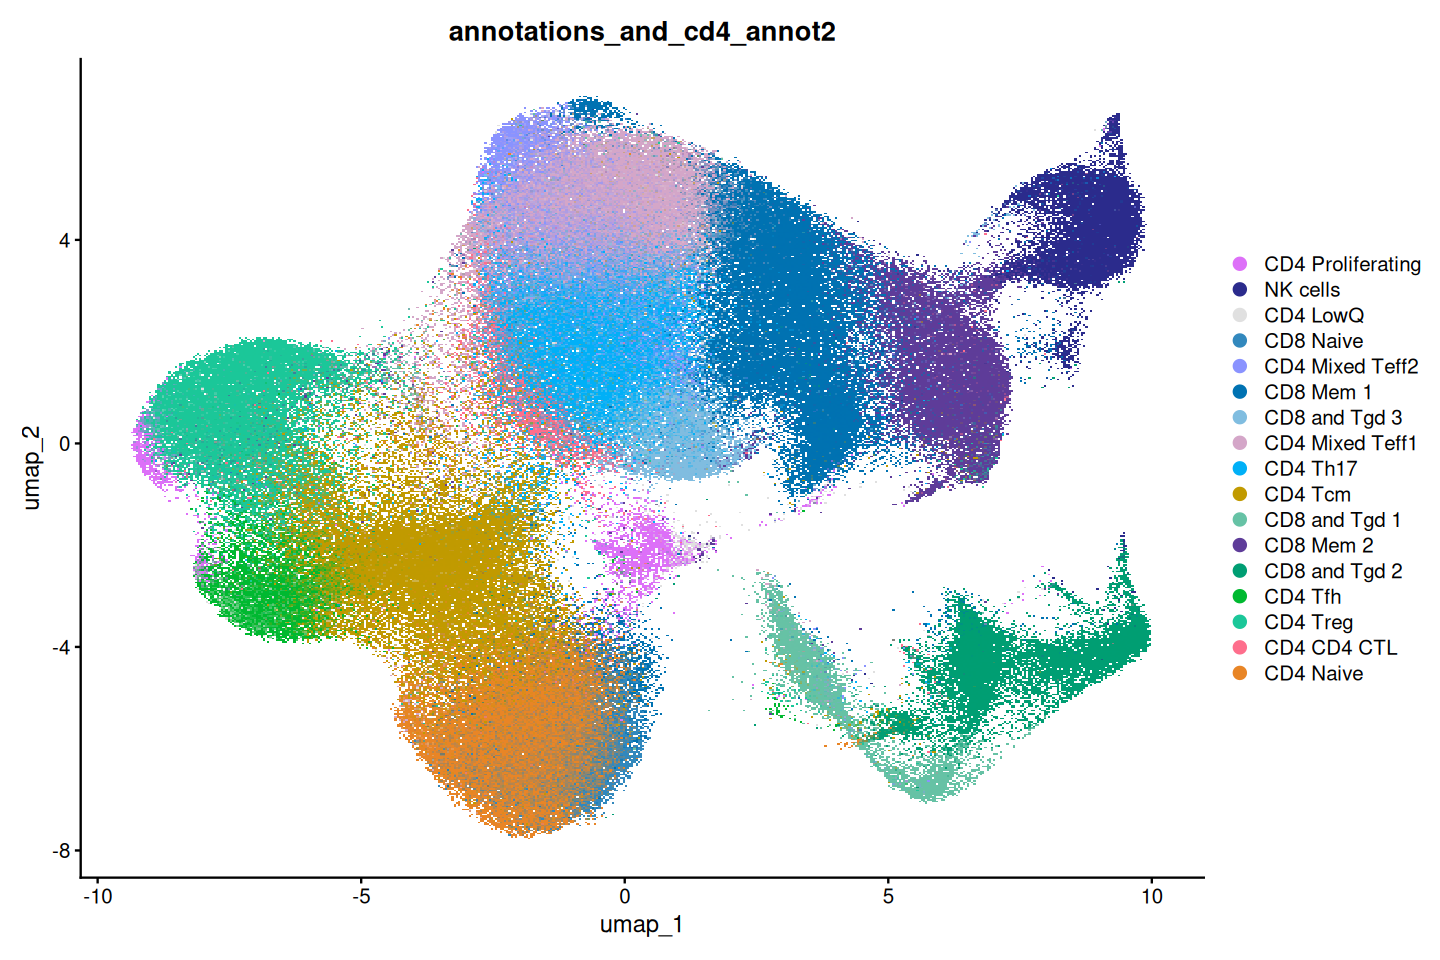

In [171]:
options(repr.plot.width = 12, repr.plot.height = 8)
DimPlot(gut_allt_3p, group.by = "annotations_and_cd4_annot2", label = F, cols = pallete3, order = c("CD4 Naive", 
                                                                                                    "CD8 and Tgd2", 
                                                                                                    "CD4 CD4 CTL",
                                                                                                   "CD4 Treg", "CD4 Tfh"))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



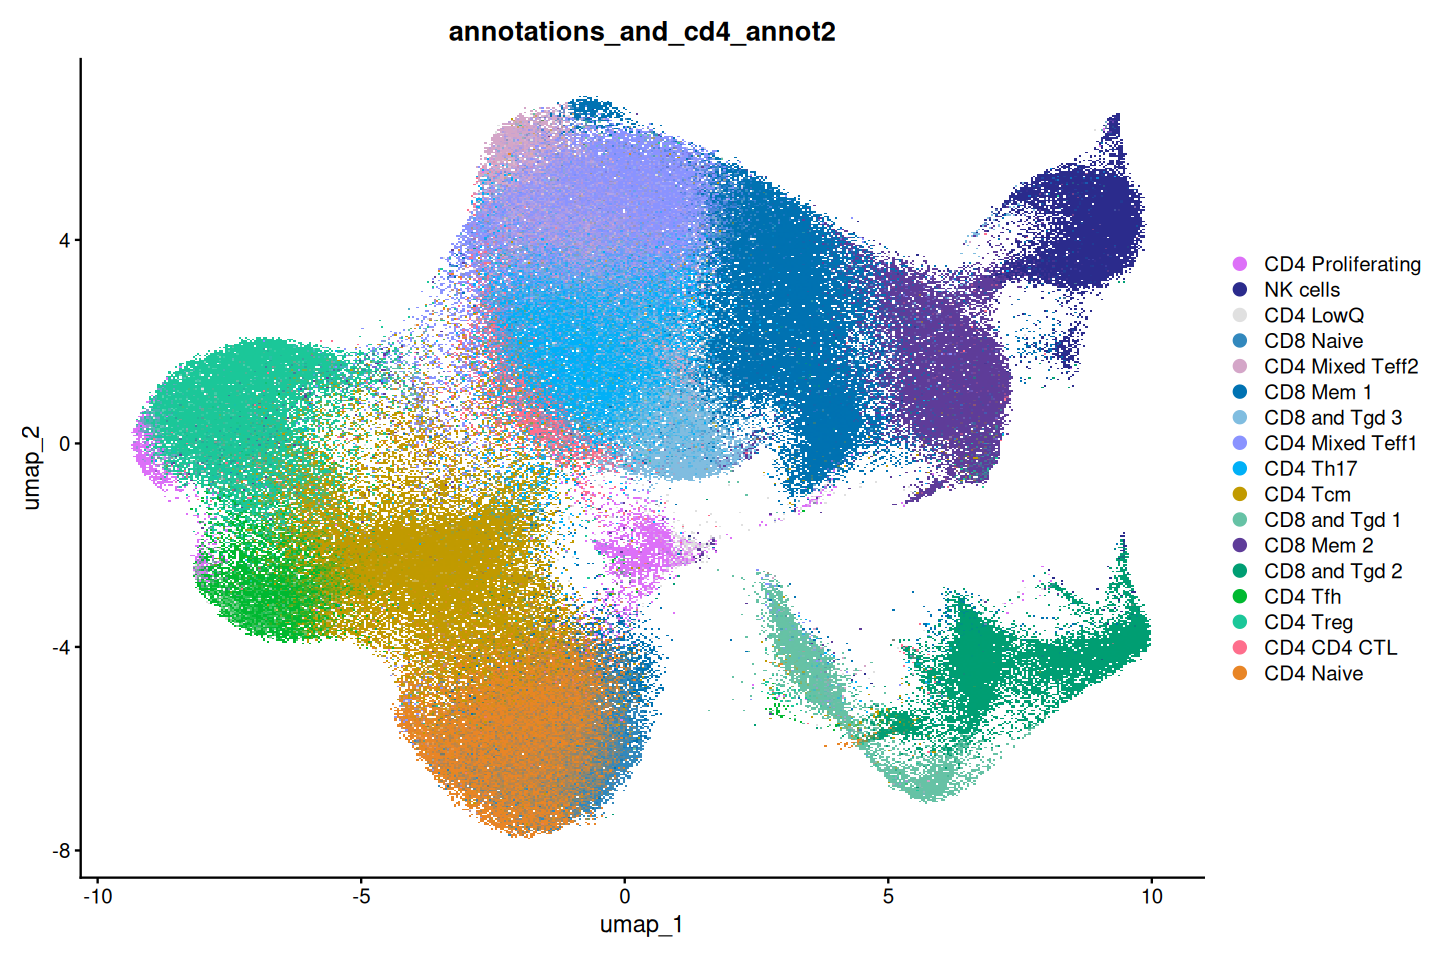

In [168]:
options(repr.plot.width = 12, repr.plot.height = 8)
DimPlot(gut_allt_3p, group.by = "annotations_and_cd4_annot2", label = F, cols = pallete3, order = c("CD4 Naive", 
                                                                                                    "CD8 and Tgd2", "CD4 CD4 CTL",
                                                                                                   "CD4 Treg", "CD4 Tfh"))

In [89]:
gut_allt_3p$annotations_and_cd4_annot2  %>% table

.
  CD4 CD4 CTL       CD4 IEL      CD4 LowQ     CD4 Naive       CD4 Tcm 
         4217          2919         19289         30663         25041 
      CD4 Tfh       CD4 Th1      CD4 Th17       CD4 Th2      CD4 Treg 
        10630         22238         17891         27327         24436 
CD8 and Tgd 1 CD8 and Tgd 2 CD8 and Tgd 3     CD8 Mem 1     CD8 Mem 2 
         5986         13543          5479         32770         18465 
    CD8 Naive      NK cells 
         9267         13116 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



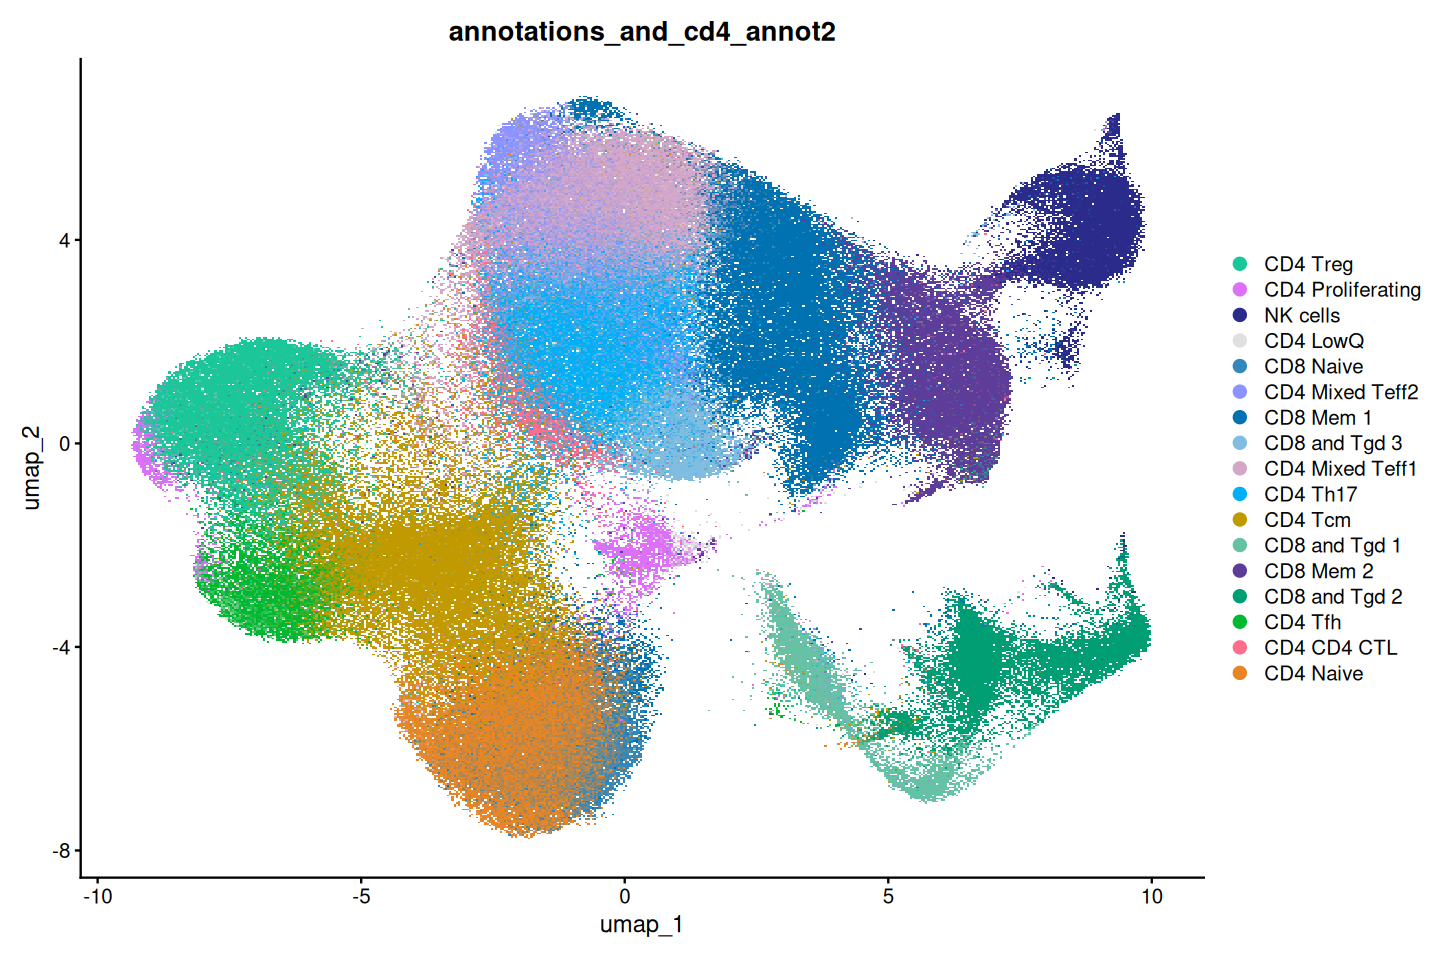

In [172]:
options(repr.plot.width = 12, repr.plot.height = 8)
DimPlot(gut_allt_3p, group.by = "annotations_and_cd4_annot2", label = F, cols = pallete3, order = c("CD4 Naive", 
                                                                                                  "CD4 CD4 CTL"
                                                                                                 ))

In [91]:
gut_allt_3p$annotations_and_cd4_annot2  %>% table

.
  CD4 CD4 CTL       CD4 IEL      CD4 LowQ     CD4 Naive       CD4 Tcm 
         4217          2919         19289         30663         25041 
      CD4 Tfh       CD4 Th1      CD4 Th17       CD4 Th2      CD4 Treg 
        10630         22238         17891         27327         24436 
CD8 and Tgd 1 CD8 and Tgd 2 CD8 and Tgd 3     CD8 Mem 1     CD8 Mem 2 
         5986         13543          5479         32770         18465 
    CD8 Naive      NK cells 
         9267         13116 

In [173]:
gut_allt_3p$annotations_with_numbers <- dplyr::recode(
  as.character(gut_allt_3p$annotations_and_cd4_annot2),

  "CD4 Naive"       = "1 CD4 Naive",
  "CD4 Tcm"         = "2 CD4 Tcm",
  "CD4 Tfh"         = "3 CD4 Tfh",
  "CD4 Treg"        = "4 CD4 Treg",
  "CD4 Mixed Teff1"         = "5 CD4 Mixed Teff1",
  "CD4 Th17"        = "6 CD4 Th17",
  "CD4 Mixed Teff2"         = "7 CD4 Mixed Teff2",
  "CD4 CD4 CTL"         = "8 CD4 CTL",
  "CD4 Proliferating"         = "9 CD4 Proliferating",

  "CD8 Naive"       = "10 CD8 Naive",
  "CD8 Mem 1"       = "11 CD8 Mem 1",
  "CD8 Mem 2"       = "12 CD8 Mem 2",
  "NK cells"        = "13 NK cells",
  "CD8 and Tgd 1"   = "14 CD8 and Tgd 1",
  "CD8 and Tgd 2"   = "15 CD8 and Tgd 2",
  "CD8 and Tgd 3"   = "16 CD8 and Tgd 3",

  "CD4 LowQ"        = "CD4 LowQ"
)

In [174]:
gut_allt_3p$annotations_with_numbers <- factor(
  gut_allt_3p$annotations_with_numbers,
  levels = c(
    "1 CD4 Naive",
    "2 CD4 Tcm",
    "3 CD4 Tfh",
    "4 CD4 Treg",
    "5 CD4 Mixed Teff1",
    "6 CD4 Th17",
    "7 CD4 Mixed Teff2",
    "8 CD4 CTL",
    "9 CD4 Proliferating",
    "10 CD8 Naive",
    "11 CD8 Mem 1",
    "12 CD8 Mem 2",
    "13 NK cells",
    "14 CD8 and Tgd 1",
    "15 CD8 and Tgd 2",
    "16 CD8 and Tgd 3",
    "CD4 LowQ"
  )
)

In [175]:
DefaultAssay(gut_allt_3p)  <- "RNA"

In [176]:
genes <- c("CD8A", "CD8B", "CD4")

# Extract expression and annotations
df <- FetchData(
  gut_allt_3p,
  vars = c(genes, "annotations_with_numbers"),
  layer = "counts"
)

# Calculate percentage of positive cells per annotation
df_summary <- df %>%
  pivot_longer(
    cols = all_of(genes),
    names_to = "gene",
    values_to = "expression"
  ) %>%
  group_by(annotations_with_numbers, gene) %>%
  summarise(
    percent_positive = mean(expression > 0) * 100,
    .groups = "drop"
  )

In [99]:
pallete3

CD4 Naive       CD4 Tcm       CD4 Tfh      CD4 Treg      CD4 Th17 
  "#e88526ff"   "#c19a00ff"   "#00b930ff"   "#1bc799ff"   "#00b0f7ff" 
      CD4 Th1       CD4 IEL       CD4 Th2   CD4 CD4 CTL CD8 and Tgd 1 
  "#8a93ffff"   "#dd70f8ff"     "#D4A6C8"   "#fe6e8cff"     "#66C2A5" 
CD8 and Tgd 2 CD8 and Tgd 3     CD8 Mem 2     CD8 Mem 1     CD8 Naive 
    "#009E73"   "#80bde0ff"     "#5E3C99"     "#0072B2"     "#3288BD" 
     NK cells      CD4 LowQ 
    "#2B2B8C"      "grey88"

In [177]:
df_summary$annotations_with_numbers  %>% table  %>% names

[1] "1 CD4 Naive"         "2 CD4 Tcm"           "3 CD4 Tfh"          
 [4] "4 CD4 Treg"          "5 CD4 Mixed Teff1"   "6 CD4 Th17"         
 [7] "7 CD4 Mixed Teff2"   "8 CD4 CTL"           "9 CD4 Proliferating"
[10] "10 CD8 Naive"        "11 CD8 Mem 1"        "12 CD8 Mem 2"       
[13] "13 NK cells"         "14 CD8 and Tgd 1"    "15 CD8 and Tgd 2"   
[16] "16 CD8 and Tgd 3"    "CD4 LowQ"

In [178]:
palette4 <- c(
  "1 CD4 Naive"      = "#e88526ff",
  "2 CD4 Tcm"        = "#c19a00ff",
  "3 CD4 Tfh"        = "#00b930ff",
  "4 CD4 Treg"       = "#1bc799ff",
  "5 CD4 Mixed Teff1"        = "#8a93ffff",
  "6 CD4 Th17"       = "#00b0f7ff",
  "7 CD4 Mixed Teff2"        = "#D4A6C8",
  "8 CD4 CTL"        = "#fe6e8cff",
  "9 CD4 Proliferating"        = "#dd70f8ff",
  "10 CD8 Naive"     = "#3288BD",
  "11 CD8 Mem 1"     = "#0072B2",
  "12 CD8 Mem 2"     = "#5E3C99",
  "13 NK cells"      = "#2B2B8C",
  "14 CD8 and Tgd 1" = "#66C2A5",
  "15 CD8 and Tgd 2" = "#009E73",
  "16 CD8 and Tgd 3" = "#80bde0ff",
  "CD4 LowQ"         = "grey88"
)

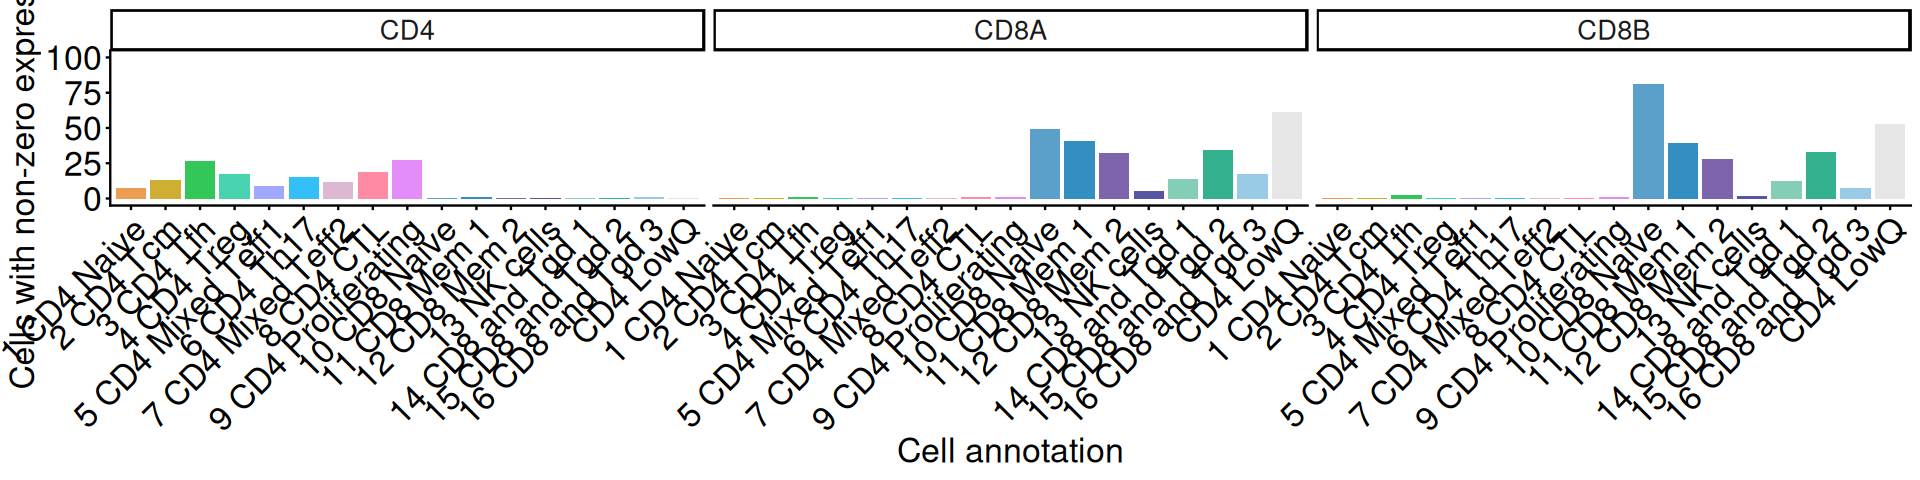

In [179]:
options(repr.plot.width = 16, repr.plot.height = 4)
ggplot(df_summary,
       aes(x = annotations_with_numbers,
           y = percent_positive,
           fill = annotations_with_numbers)) +
  geom_col(width = 0.85, alpha = 0.8) +
  facet_wrap(~ gene, nrow = 1) +
  scale_fill_manual(values = palette4) +
  scale_y_continuous(limits = c(0, 100)) +
  labs(
    x = "Cell annotation",
    y = "Cells with non-zero expression (%)"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "none"
  ) +
ggtheme()

In [180]:
df_summary

annotations_with_numbers,gene,percent_positive
<fct>,<chr>,<dbl>
1 CD4 Naive,CD4,7.26280437
1 CD4 Naive,CD8A,0.07104566
1 CD4 Naive,CD8B,0.12594458
2 CD4 Tcm,CD4,12.53351005
2 CD4 Tcm,CD8A,0.06927920
2 CD4 Tcm,CD8B,0.11446128
3 CD4 Tfh,CD4,26.38578175
3 CD4 Tfh,CD8A,0.45985583
3 CD4 Tfh,CD8B,2.23713647


In [111]:
df_summary

annotations_with_numbers,gene,percent_positive
<fct>,<chr>,<dbl>
1 CD4 Naive,CD4,6.6627532
1 CD4 Naive,CD8A,0.0000000
1 CD4 Naive,CD8B,0.0000000
2 CD4 Tcm,CD4,11.1297472
2 CD4 Tcm,CD8A,0.0000000
2 CD4 Tcm,CD8B,0.0000000
3 CD4 Tfh,CD4,19.7365945
3 CD4 Tfh,CD8A,0.0000000
3 CD4 Tfh,CD8B,0.0000000


In [181]:

ggsave("figures/barplot_gut_cd4_cd8_3p_updated.svg", width = 34, height = 12.5, units = "cm")
ggsave("figures/barplot_gut_cd4_cd8_3p_updated.png", width = 34, height = 12.5, units = "cm")